# Bước C2 (phần so sánh) - 5 lõi của mô hình chung Sequential Forecast (LSTM, GRU, Transformer, S4D, Mamba), 8 cấu hình x 3 hạt giống (111, 222, 333), 30 epoch, chọn best_model.pt theo NSE trung vị validation, test chấm mọi epoch.
# Kiểm 24 run, bảng so 5 lõi với B* và nhiễu hạt giống, so C1 hạt giống 111 với C2 hạt giống 111, NPZ test/S0/hạn 1 cho bộ đánh giá, tổ hợp 3 hạt giống, chi phí, hình, chọn cấu hình bước H và mô hình demo theo validation.
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 5.2 (chạy chính thức,
 báo cáo), 5.3 (nhiễu hạt giống), 6.1 (chỉ NSE trung vị validation dùng để chọn), 6.5 (chi phí), 7 (dòng C2, H),
 9.6 (mô hình demo). Hợp đồng NPZ: Workspace/06_Evaluation/01_Evaluation_LamaHCEExt/01_Evaluation_LamaHCEExt.md Mục 7.
# Notebook Kaggle "13_C2_LamaHCEExt_Compare": Accelerator = None (CPU), Internet = Off, Persistence = Files only,
 Environment = Pin to original environment. Add Input (34):
   - Output 24 notebook C2: cấu hình x1 => 12_C2_Train_<cấu hình>_Seed<N>; cấu hình x3 => 12_C2_Train_<cấu hình>_Seed<N>_Cont
     (thư mục run trong Output _Cont đủ 30 epoch);
   - Output 8 notebook C1 vòng 2 của đúng 8 cấu hình C2: 10_C1_Tune_<cấu hình>_Cont;
   - Output 09_B3_LamaHCEExt_Compare Version 1 (B* = B3 P10S12, ba hạt giống, ngưỡng nhiễu);
   - Output 02_A3_LamaHCEExt_Benchmarks Version 1 (lịch, ID, diện tích, obs, persistence cho NPZ).
 Không cần GPU, không cần NeuralHydrology: đọc config.yml, csv chỉ số, output.log, test_results.p (pickle xarray).
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Tìm Output 24 run C2, 8 run C1, B3 Compare, A3; kiểm sha256, danh tính, giao thức, cấu hình
   Phần 2 - Bảng 24 run và 8 cấu hình: trung bình +- SD 3 hạt giống, hiệu so với B* theo bội nhiễu hạt giống
   Phần 3 - C1 so với C2 cùng hạt giống 111: trọng số từng epoch, NSE validation từng epoch, epoch chọn
   Phần 4 - 24 NPZ test/S0/hạn 1 theo hợp đồng bộ đánh giá, kiểm đọc ngược và NSE tính lại
   Phần 5 - Tổ hợp 3 hạt giống: NSE, KGE trung vị test của dự báo trung bình so với từng hạt giống (cả B*)
   Phần 6 - Chi phí: tham số, phút huấn luyện/validation mỗi epoch, phút chấm test, giờ huấn luyện, GPU đỉnh; tỉ số so LSTM
   Phần 7 - Hình (8 hình riêng): đường NSE theo epoch, so với B*, chất lượng theo chi phí, chạy lại cùng hạt giống
   Phần 8 - Chọn cấu hình bước H và mô hình demo theo validation; bàn giao 24 checkpoint; c2_summary, environment, manifest

bước,cấu hình,hạt giống,notebook,thư mục run,commit,trạng thái,epoch huấn luyện,model_epoch,validation,test,epoch chọn,epoch NSE val cao nhất,số tham số,mốc,lệch tham số,chốt chặn: bước bỏ,tệp manifest,lệch sha256,lỗi
C2,lstm_L2_x1_lr1e-3,111,12_C2_Train_lstm_L2_x1_lr1e-3_Seed111,C2_lstm_L2_x1_lr1e-3_seed111_0711_152841,db6dc1f,xong,30,30,30,30,24,24,84106,84865,-0.894%,-,10,0,-
C2,lstm_L2_x1_lr1e-3,222,12_C2_Train_lstm_L2_x1_lr1e-3_Seed222,C2_lstm_L2_x1_lr1e-3_seed222_0711_155545,db6dc1f,xong,30,30,30,30,20,20,84106,84865,-0.894%,-,10,0,-
C2,lstm_L2_x1_lr1e-3,333,12_C2_Train_lstm_L2_x1_lr1e-3_Seed333,C2_lstm_L2_x1_lr1e-3_seed333_0811_161058,db6dc1f,xong,30,30,30,30,22,22,84106,84865,-0.894%,-,10,0,-
C2,gru_L2_x1_lr1e-3,111,12_C2_Train_gru_L2_x1_lr1e-3_Seed111,C2_gru_L2_x1_lr1e-3_seed111_0911_085539,db6dc1f,xong,30,30,30,30,20,20,84503,84865,-0.427%,-,10,0,-
C2,gru_L2_x1_lr1e-3,222,12_C2_Train_gru_L2_x1_lr1e-3_Seed222,C2_gru_L2_x1_lr1e-3_seed222_1311_020752,db6dc1f,xong,30,30,30,30,26,26,84503,84865,-0.427%,1.0000,10,0,-
C2,gru_L2_x1_lr1e-3,333,12_C2_Train_gru_L2_x1_lr1e-3_Seed333,C2_gru_L2_x1_lr1e-3_seed333_0911_085438,db6dc1f,xong,30,30,30,30,14,14,84503,84865,-0.427%,-,10,0,-
C2,transformer_L2_x1_lr1e-3,111,12_C2_Train_transformer_L2_x1_lr1e-3_Seed111,C2_transformer_L2_x1_lr1e-3_seed111_0811_153016,db6dc1f,xong,30,30,30,30,24,24,84823,84865,-0.049%,-,10,0,-
C2,transformer_L2_x1_lr1e-3,222,12_C2_Train_transformer_L2_x1_lr1e-3_Seed222,C2_transformer_L2_x1_lr1e-3_seed222_0811_160856,db6dc1f,xong,30,30,30,30,28,28,84823,84865,-0.049%,-,10,0,-
C2,transformer_L2_x1_lr1e-3,333,12_C2_Train_transformer_L2_x1_lr1e-3_Seed333,C2_transformer_L2_x1_lr1e-3_seed333_0811_160722,db6dc1f,xong,30,30,30,30,30,30,84823,84865,-0.049%,-,10,0,-
C2,transformer_L2_x3_lr5e-4,111,12_C2_Train_transformer_L2_x3_lr5e-4_Seed111_Cont,C2_transformer_L2_x3_lr5e-4_seed111_0811_165525,db6dc1f,xong,30,30,30,30,29,29,254425,84865,-0.067%,-,10,0,-


mục,giá trị,cần,đạt
Run C2 có đủ,24 / 24,24 (8 cấu hình x 3 hạt giống),ĐẠT
Run C1 hạt giống 111 có đủ,8 / 8,8,ĐẠT
Run không lỗi,32 / 32,tất cả,ĐẠT
Mốc tham số chung,[84865],một giá trị,ĐẠT
Config C2 giống nhau ngoài khóa riêng,0 khóa lệch,0,ĐẠT
Chốt chặn gradient,{'gru_L2_x1_lr1e-3 seed222': 1.0},"chỉ [('gru_L2_x1_lr1e-3', 222)]",ĐẠT
"B3 Compare: manifest, summary","14 / 14 tệp, complete=True","đủ, True",ĐẠT
B* = B3 P10S12 ba hạt giống,"[111, 222, 333]","[111, 222, 333]",ĐẠT
Ngưỡng nhiễu hạt giống (SD NSE trung vị validation B0),0.00793,> 0,ĐẠT
Thiếu Output,không,không,ĐẠT


=> Đạt. Chạy Phần 2.


cấu hình,lõi,độ sâu,mức,lr,hạt giống,epoch chọn,số tham số,NSE validation,NSE test,KGE test,chốt chặn: bước bỏ
lstm_L2_x1_lr1e-3,lstm,2,1,0.0010,111,24,84106,0.7679,0.7166,0.7801,-
lstm_L2_x1_lr1e-3,lstm,2,1,0.0010,222,20,84106,0.7672,0.7191,0.7724,-
lstm_L2_x1_lr1e-3,lstm,2,1,0.0010,333,22,84106,0.7681,0.7180,0.7627,-
gru_L2_x1_lr1e-3,gru,2,1,0.0010,111,20,84503,0.7707,0.7065,0.7775,-
gru_L2_x1_lr1e-3,gru,2,1,0.0010,222,26,84503,0.7650,0.7171,0.7721,1.0000
gru_L2_x1_lr1e-3,gru,2,1,0.0010,333,14,84503,0.7702,0.7115,0.7972,-
transformer_L2_x1_lr1e-3,transformer,2,1,0.0010,111,24,84823,0.7359,0.6982,0.7731,-
transformer_L2_x1_lr1e-3,transformer,2,1,0.0010,222,28,84823,0.7479,0.7094,0.7735,-
transformer_L2_x1_lr1e-3,transformer,2,1,0.0010,333,30,84823,0.7344,0.6968,0.7784,-
transformer_L2_x3_lr5e-4,transformer,2,3,0.0005,111,29,254425,0.7296,0.6926,0.7689,-


hạng,cấu hình,hạt giống,epoch chọn,NSE validation,hiệu validation - B*,bội nhiễu,NSE test,hiệu test - B*,KGE test
1,gru_L2_x1_lr1e-3,3,14-26,0.7686 ± 0.0031,+0.0017,+0.22,0.7117 ± 0.0053,-0.0055,0.7823 ± 0.0132
2,lstm_L2_x1_lr1e-3,3,20-24,0.7677 ± 0.0005,+0.0008,+0.10,0.7179 ± 0.0013,+0.0007,0.7717 ± 0.0087
3,mamba_L4_x3_lr1e-3,3,12-29,0.7662 ± 0.0022,-0.0007,-0.09,0.7112 ± 0.0049,-0.0059,0.7721 ± 0.0122
4,mamba_L2_x1_lr1e-3,3,15-25,0.7630 ± 0.0042,-0.0039,-0.49,0.7204 ± 0.0055,+0.0032,0.7640 ± 0.0172
5,s4d_L4_x3_lr1e-3,3,10-20,0.7415 ± 0.0008,-0.0254,-3.20,0.6963 ± 0.0056,-0.0209,0.7367 ± 0.0093
6,s4d_L4_x1_lr1e-3,3,12-22,0.7401 ± 0.0038,-0.0268,-3.38,0.6931 ± 0.0049,-0.0241,0.7282 ± 0.0015
7,transformer_L2_x3_lr5e-4,3,21-29,0.7395 ± 0.0087,-0.0274,-3.45,0.6960 ± 0.0033,-0.0212,0.7535 ± 0.0192
8,transformer_L2_x1_lr1e-3,3,24-30,0.7394 ± 0.0074,-0.0275,-3.47,0.7015 ± 0.0069,-0.0157,0.7750 ± 0.0030
-,"B* (B3 P10S12, SeqLSTM)",3,14-23,0.7669 ± 0.0050,0,0,0.7172 ± 0.0031,0,0.7680 ± 0.0134


lõi,cấu hình,mức,NSE validation,bội nhiễu so B*,NSE test,hạng validation
lstm,lstm_L2_x1_lr1e-3,x1,0.7677 ± 0.0005,+0.10,0.7179 ± 0.0013,2
gru,gru_L2_x1_lr1e-3,x1,0.7686 ± 0.0031,+0.22,0.7117 ± 0.0053,1
transformer,transformer_L2_x1_lr1e-3,x1,0.7394 ± 0.0074,-3.47,0.7015 ± 0.0069,8
transformer,transformer_L2_x3_lr5e-4,x3,0.7395 ± 0.0087,-3.45,0.6960 ± 0.0033,7
s4d,s4d_L4_x1_lr1e-3,x1,0.7401 ± 0.0038,-3.38,0.6931 ± 0.0049,6
s4d,s4d_L4_x3_lr1e-3,x3,0.7415 ± 0.0008,-3.20,0.6963 ± 0.0056,5
mamba,mamba_L2_x1_lr1e-3,x1,0.7630 ± 0.0042,-0.49,0.7204 ± 0.0055,4
mamba,mamba_L4_x3_lr1e-3,x3,0.7662 ± 0.0022,-0.09,0.7112 ± 0.0049,3


... (6 outputs left out)

cấu hình,hạt giống,NSE test từng hạt giống,NSE TB hạt giống,NSE tổ hợp,lợi NSE,lợi NSE so hạt giống tốt nhất,KGE TB hạt giống,KGE tổ hợp,lợi KGE,lưu vực tổ hợp > mọi hạt giống
lstm_L2_x1_lr1e-3,3,0.7166 / 0.7191 / 0.7180,0.7179,0.7351,0.0171,0.0159,0.7717,0.7767,0.0050,218 / 451
gru_L2_x1_lr1e-3,3,0.7065 / 0.7171 / 0.7115,0.7117,0.7329,0.0212,0.0158,0.7823,0.7906,0.0084,235 / 451
transformer_L2_x1_lr1e-3,3,0.6982 / 0.7094 / 0.6968,0.7015,0.7106,0.0092,0.0012,0.7750,0.7814,0.0064,165 / 451
transformer_L2_x3_lr5e-4,3,0.6926 / 0.6992 / 0.6962,0.6960,0.7136,0.0176,0.0144,0.7535,0.7562,0.0027,191 / 451
s4d_L4_x1_lr1e-3,3,0.6985 / 0.6887 / 0.6921,0.6931,0.7127,0.0196,0.0142,0.7282,0.7320,0.0038,219 / 451
s4d_L4_x3_lr1e-3,3,0.7027 / 0.6927 / 0.6936,0.6963,0.7114,0.0151,0.0087,0.7367,0.7434,0.0068,238 / 451
mamba_L2_x1_lr1e-3,3,0.7261 / 0.7152 / 0.7198,0.7204,0.7330,0.0126,0.0069,0.7640,0.7766,0.0126,232 / 451
mamba_L4_x3_lr1e-3,3,0.7090 / 0.7169 / 0.7078,0.7112,0.7338,0.0225,0.0169,0.7721,0.7848,0.0127,229 / 451
B* (B3 P10S12),3,0.7200 / 0.7139 / 0.7177,0.7172,0.7291,0.0119,0.0091,0.7680,0.7751,0.0071,191 / 451


KGE tính lại từng hạt giống khớp test_metrics.csv (<= 0.0001) ở cả 24 run. Lợi tổ hợp NSE +0.0092 đến +0.0225.


cấu hình,hạt giống,số tham số,phiên,phút huấn luyện/epoch,phút validation/epoch,phút chấm test 451 lưu vực,giờ huấn luyện 30 epoch,GPU đỉnh MiB,NSE validation,NSE test
lstm_L2_x1_lr1e-3,3,"84,106",1,3.20 (x1.00),0.80 (x1.00),0.79 (x1.00),2.06 (1.98-2.06),"2,381 (x1.00)",0.7677,0.7179
gru_L2_x1_lr1e-3,3,"84,503",1,3.46 (x1.08),0.88 (x1.10),0.88 (x1.11),2.23 (2.17-2.30),"2,585 (x1.09)",0.7686,0.7117
transformer_L2_x1_lr1e-3,3,"84,823",1,9.28 (x2.91),3.04 (x3.77),3.05 (x3.85),6.23 (6.18-6.24),"3,043 (x1.28)",0.7394,0.7015
transformer_L2_x3_lr5e-4,3,"254,425",2,14.14 (x4.43),4.04 (x5.02),4.31 (x5.44),9.14 (8.99-9.61),"3,545 (x1.49)",0.7395,0.6960
s4d_L4_x1_lr1e-3,3,"84,449",1,10.30 (x3.22),2.42 (x3.01),2.42 (x3.05),6.41 (6.35-6.84),"2,419 (x1.02)",0.7401,0.6931
s4d_L4_x3_lr1e-3,3,"255,833",2,22.55 (x7.06),5.48 (x6.81),5.25 (x6.62),13.82 (13.61-14.17),"4,147 (x1.74)",0.7415,0.6963
mamba_L2_x1_lr1e-3,3,"85,039",1,8.76 (x2.74),1.70 (x2.12),1.70 (x2.15),5.29 (5.02-5.35),"1,815 (x0.76)",0.7630,0.7204
mamba_L4_x3_lr1e-3,3,"254,677",2,23.46 (x7.34),4.53 (x5.63),4.57 (x5.77),14.32 (13.02-14.96),"2,709 (x1.14)",0.7662,0.7112


Tổng giờ huấn luyện 24 run C2 (train + validation, không tính chấm test mọi epoch): 178.4 giờ


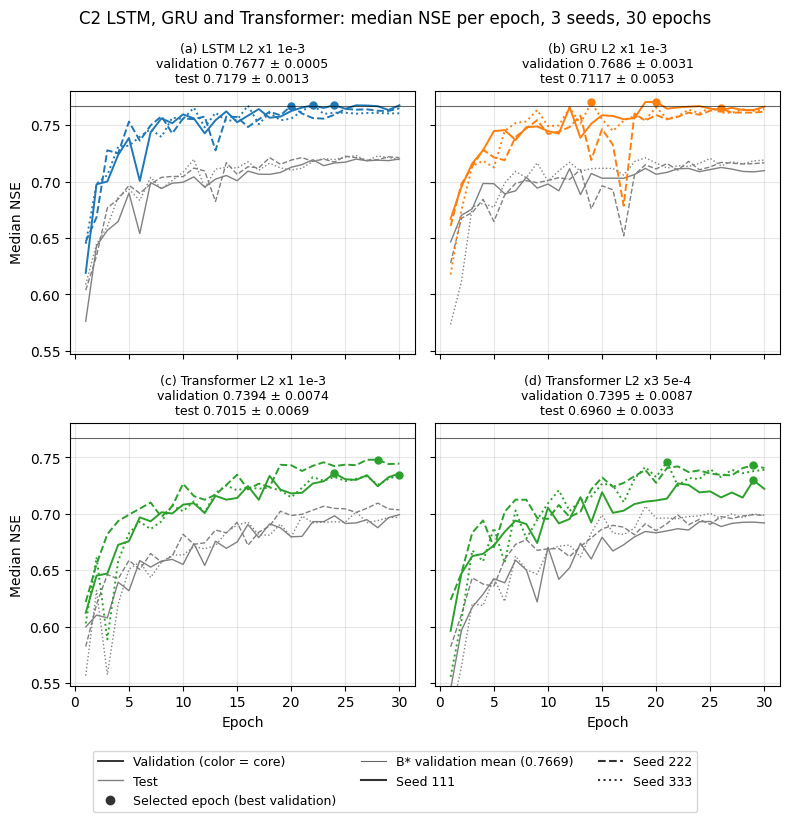

Hình: Nhóm LSTM, GRU, Transformer; mỗi ô một cấu hình C2, nét màu là NSE trung vị validation, nét xám là test, kiểu nét phân biệt hạt giống, chấm tròn là epoch được chọn theo validation, đường đen là trung bình validation của B* (0,7669); tiêu đề ô ghi trung bình ± độ lệch chuẩn 3 hạt giống. Epoch chọn từ 14 tới 30; 4 run chọn epoch >= 28 (Transformer L2 x1 1e-3 seed 222, Transformer L2 x1 1e-3 seed 333, Transformer L2 x3 5e-4 seed 111, Transformer L2 x3 5e-4 seed 222), tức còn tăng khi lịch cosine kết thúc ở epoch 30. Trục dọc từ 0,55 (chung hai hình): 4 điểm ở epoch 1-2 thấp hơn, nhỏ nhất 0,434, nằm ngoài trục.


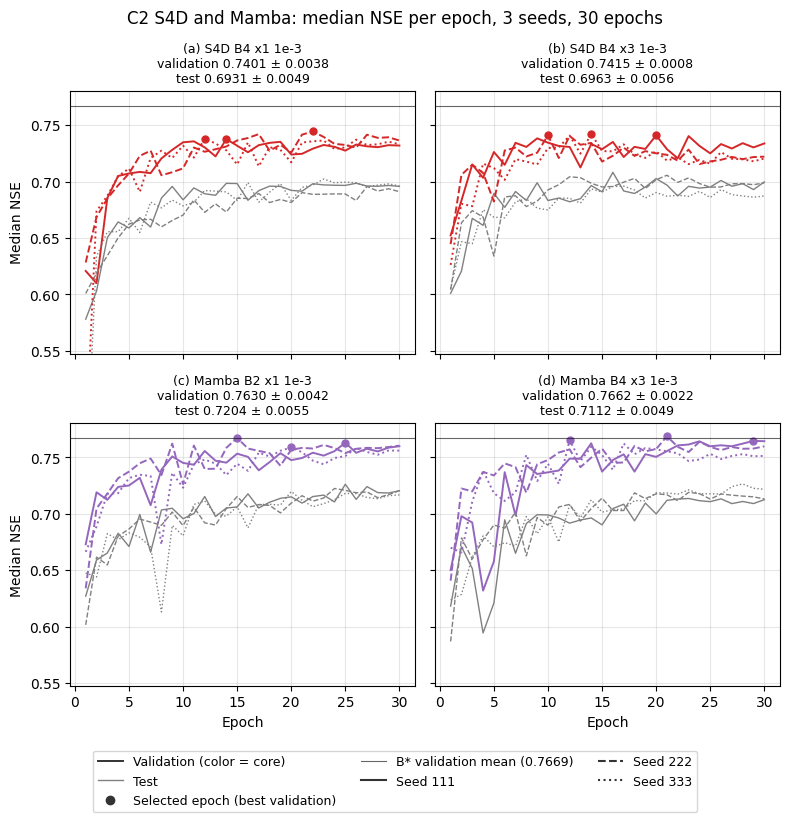

Hình: Nhóm S4D, Mamba; mỗi ô một cấu hình C2, nét màu là NSE trung vị validation, nét xám là test, kiểu nét phân biệt hạt giống, chấm tròn là epoch được chọn theo validation, đường đen là trung bình validation của B* (0,7669); tiêu đề ô ghi trung bình ± độ lệch chuẩn 3 hạt giống. Epoch chọn từ 10 tới 29; 1 run chọn epoch >= 28 (Mamba B4 x3 1e-3 seed 111), tức còn tăng khi lịch cosine kết thúc ở epoch 30. Trục dọc từ 0,55 (chung hai hình): 4 điểm ở epoch 1-2 thấp hơn, nhỏ nhất 0,434, nằm ngoài trục.


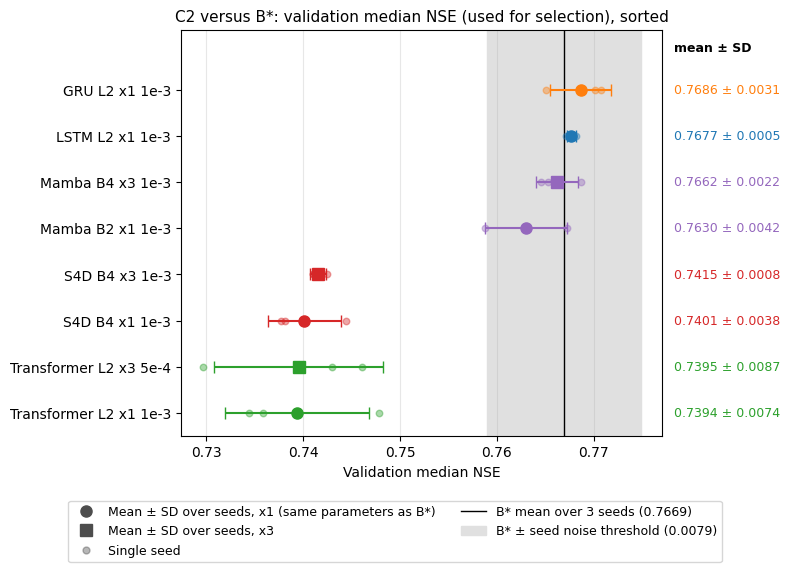

Hình: NSE trung vị validation của 8 cấu hình C2, xếp từ cao xuống thấp; điểm đậm và thanh ngang là trung bình ± độ lệch chuẩn 3 hạt giống (số ở cột phải), chấm mờ là từng hạt giống; vạch đen là B* (0,7669), dải xám là B* ± ngưỡng nhiễu 0,0079. Trong nhiễu của B*: GRU L2 x1 1e-3, LSTM L2 x1 1e-3, Mamba B4 x3 1e-3, Mamba B2 x1 1e-3; kém nhất Transformer L2 x1 1e-3 (-3,5 lần ngưỡng nhiễu).


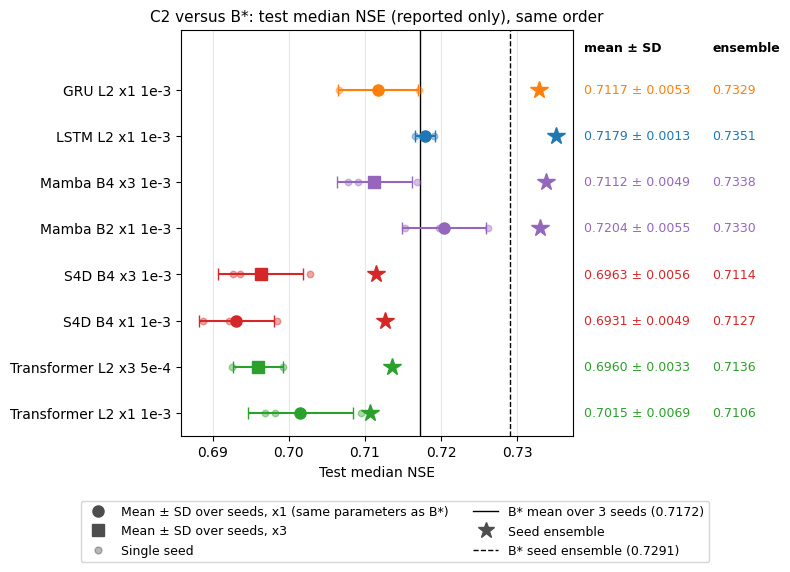

Hình: NSE trung vị test, cùng thứ tự với hình validation (test chỉ báo cáo, không dùng để chọn); sao là dự báo tổ hợp (trung bình 3 hạt giống, số ở cột phải); vạch đen là B* (0,7172), vạch đứt là tổ hợp B* (0,7291). Tổ hợp tăng NSE test 0,009-0,023 so với trung bình từng hạt giống.


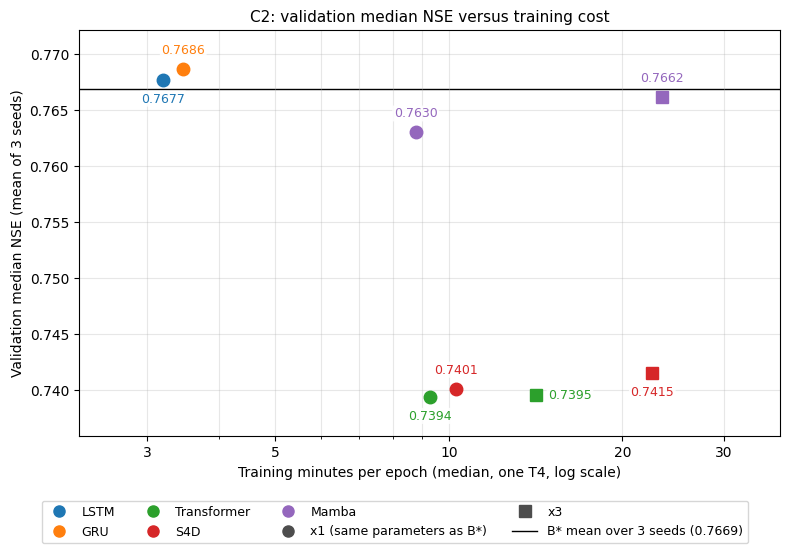

Hình: Trục ngang là phút huấn luyện mỗi epoch trên một T4 (thang log), trục dọc là NSE trung vị validation trung bình 3 hạt giống (số cạnh điểm; độ lệch chuẩn ở hình so với B*); tròn là mức cùng tham số với B*, vuông là mức gấp 3; vạch đen là B* (0,7669). So với LSTM (3,20 phút/epoch), các cấu hình khác tốn 1,08-7,34 lần; số đo phụ thuộc cài đặt cụ thể (cuDNN cho LSTM/GRU, mamba-ssm, S4D thuần PyTorch), không phải độ phức tạp thuật toán.


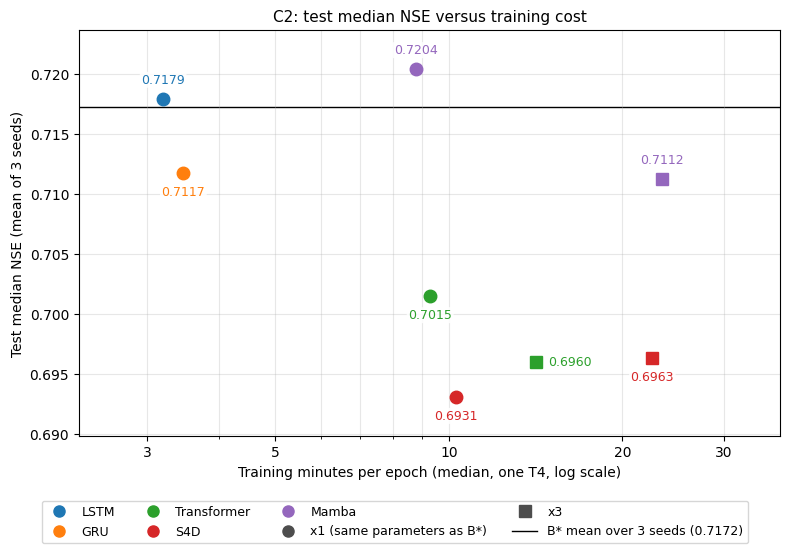

Hình: Trục ngang là phút huấn luyện mỗi epoch trên một T4 (thang log), trục dọc là NSE trung vị test trung bình 3 hạt giống (số cạnh điểm; độ lệch chuẩn ở hình so với B*); tròn là mức cùng tham số với B*, vuông là mức gấp 3; vạch đen là B* (0,7172). So với LSTM (3,20 phút/epoch), các cấu hình khác tốn 1,08-7,34 lần; số đo phụ thuộc cài đặt cụ thể (cuDNN cho LSTM/GRU, mamba-ssm, S4D thuần PyTorch), không phải độ phức tạp thuật toán.


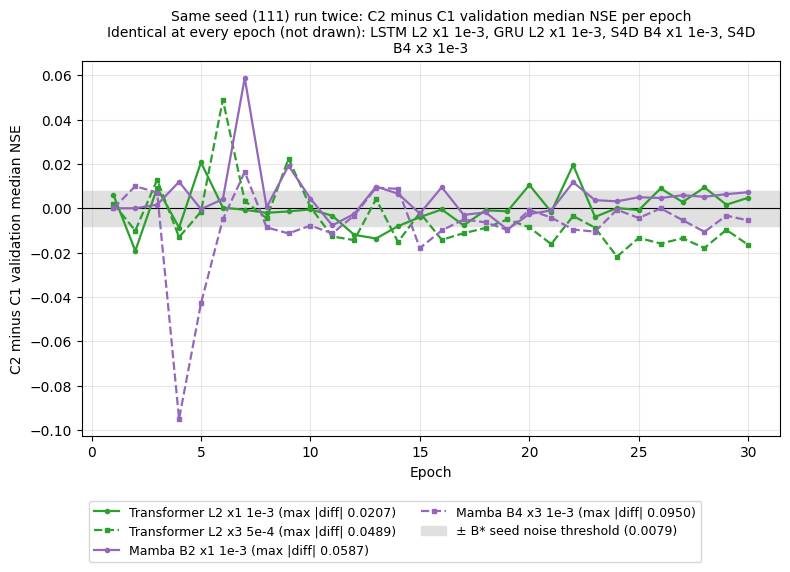

Hình: Cùng hạt giống 111, cùng mã và config, chạy hai lần (C1: epoch 1-15 rồi chạy tiếp tới 30; C2: liền 30 epoch); đường là hiệu NSE trung vị validation C2 - C1 từng epoch, dải xám là ± ngưỡng nhiễu hạt giống 0,0079. Hiệu 0 ở mọi epoch: LSTM L2 x1 1e-3, GRU L2 x1 1e-3, S4D B4 x1 1e-3, S4D B4 x3 1e-3 => chạy tiếp qua hai phiên không đổi kết quả; Transformer, Mamba lệch ngay từ epoch đầu do phép tính không tất định trên GPU.


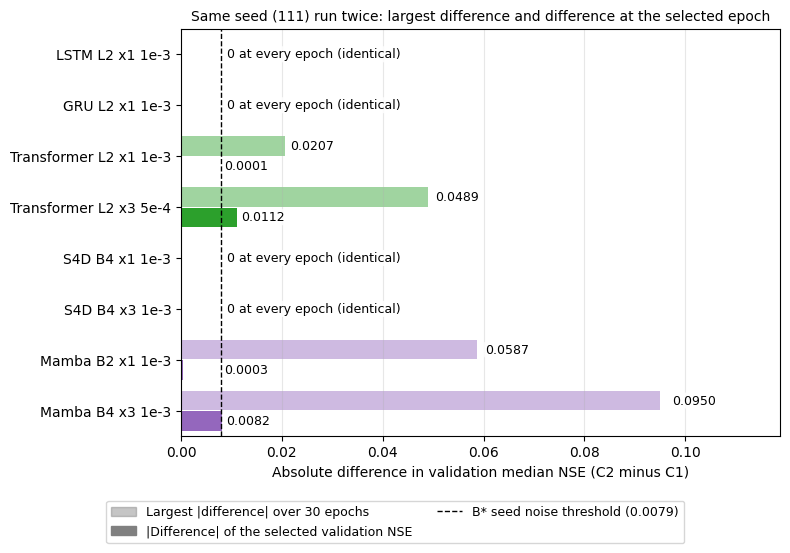

Hình: Thanh nhạt là lệch lớn nhất của NSE trung vị validation giữa hai lần chạy cùng hạt giống 111 qua 30 epoch, thanh đậm là lệch của NSE validation được chọn (epoch tốt nhất của mỗi lần), vạch đứt là ngưỡng nhiễu hạt giống 0,0079. Transformer, Mamba: lệch lớn nhất 0,021-0,095, ở NSE được chọn tới 0,011, cỡ ngưỡng nhiễu => với hai lõi này, khác biệt giữa các hạt giống gồm cả phần không tất định của GPU.


việc,chọn,luật,NSE val,NSE test (báo cáo)
LSTM bước H,lstm_L2_x1_lr1e-3,cấu hình LSTM của C2,0.7677 ± 0.0005,0.7179 ± 0.0013
Lõi SSM bước H,mamba_L4_x3_lr1e-3,"S4D/Mamba trung bình 3 hạt giống cao nhất, không ngưỡng",0.7662 ± 0.0022,0.7112 ± 0.0049
Mô hình demo,gru_L2_x1_lr1e-3 seed111,run NSE val cao nhất trong 24,0.7707,0.7065


conf,n_seeds,val_mean,val_sd,test_mean,test_sd,cách cấu hình đầu (bội nhiễu)
mamba_L4_x3_lr1e-3,3,0.7662,0.0022,0.7112,0.0049,0.0000
mamba_L2_x1_lr1e-3,3,0.7630,0.0042,0.7204,0.0055,-0.4044
s4d_L4_x3_lr1e-3,3,0.7415,0.0008,0.6963,0.0056,-3.1125
s4d_L4_x1_lr1e-3,3,0.7401,0.0038,0.6931,0.0049,-3.2892


cấu hình,hạt giống,notebook,thư mục run,epoch chọn,NSE val,NSE test,sha256 best_model.pt,sha256 config.yml,sha256 train_data_scaler.yml,NPZ
lstm_L2_x1_lr1e-3,111,12_C2_Train_lstm_L2_x1_lr1e-3_Seed111,c_runs/C2_lstm_L2_x1_lr1e-3_seed111_0711_152841,24,0.7679,0.7166,d41a8a853436,0341f37894aa,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_C2_seed111_test_S0_lead1.npz
lstm_L2_x1_lr1e-3,222,12_C2_Train_lstm_L2_x1_lr1e-3_Seed222,c_runs/C2_lstm_L2_x1_lr1e-3_seed222_0711_155545,20,0.7672,0.7191,fab6d821a5f8,c559857f3a26,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_C2_seed222_test_S0_lead1.npz
lstm_L2_x1_lr1e-3,333,12_C2_Train_lstm_L2_x1_lr1e-3_Seed333,c_runs/C2_lstm_L2_x1_lr1e-3_seed333_0811_161058,22,0.7681,0.7180,e9039701ce39,a388f1b5e3a2,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_C2_seed333_test_S0_lead1.npz
gru_L2_x1_lr1e-3,111,12_C2_Train_gru_L2_x1_lr1e-3_Seed111,c_runs/C2_gru_L2_x1_lr1e-3_seed111_0911_085539,20,0.7707,0.7065,07069a5b957e,c27fad175c75,baae107de375,contracts/SF_gru_L2_x1_lr1e-3_C2_seed111_test_S0_lead1.npz
gru_L2_x1_lr1e-3,222,12_C2_Train_gru_L2_x1_lr1e-3_Seed222,c_runs/C2_gru_L2_x1_lr1e-3_seed222_1311_020752,26,0.7650,0.7171,829a4a04a85c,33fbeef0b478,baae107de375,contracts/SF_gru_L2_x1_lr1e-3_C2_seed222_test_S0_lead1.npz
gru_L2_x1_lr1e-3,333,12_C2_Train_gru_L2_x1_lr1e-3_Seed333,c_runs/C2_gru_L2_x1_lr1e-3_seed333_0911_085438,14,0.7702,0.7115,8312e499c784,70de091bb884,baae107de375,contracts/SF_gru_L2_x1_lr1e-3_C2_seed333_test_S0_lead1.npz
transformer_L2_x1_lr1e-3,111,12_C2_Train_transformer_L2_x1_lr1e-3_Seed111,c_runs/C2_transformer_L2_x1_lr1e-3_seed111_0811_153016,24,0.7359,0.6982,30e1f1990093,4aed162818d4,baae107de375,contracts/SF_transformer_L2_x1_lr1e-3_C2_seed111_test_S0_lead1.npz
transformer_L2_x1_lr1e-3,222,12_C2_Train_transformer_L2_x1_lr1e-3_Seed222,c_runs/C2_transformer_L2_x1_lr1e-3_seed222_0811_160856,28,0.7479,0.7094,76c0a52193dd,34db26ccc869,baae107de375,contracts/SF_transformer_L2_x1_lr1e-3_C2_seed222_test_S0_lead1.npz
transformer_L2_x1_lr1e-3,333,12_C2_Train_transformer_L2_x1_lr1e-3_Seed333,c_runs/C2_transformer_L2_x1_lr1e-3_seed333_0811_160722,30,0.7344,0.6968,9ae973e9c228,3f88991eef63,baae107de375,contracts/SF_transformer_L2_x1_lr1e-3_C2_seed333_test_S0_lead1.npz
transformer_L2_x3_lr5e-4,111,12_C2_Train_transformer_L2_x3_lr5e-4_Seed111_Cont,c_runs/C2_transformer_L2_x3_lr5e-4_seed111_0811_165525,29,0.7296,0.6926,156ec98c8a22,9195e3082752,baae107de375,contracts/SF_transformer_L2_x3_lr5e-4_C2_seed111_test_S0_lead1.npz


file,bytes,sha256
Figures/C2_Bstar_Test.png,181073,4fa9ad38e557
Figures/C2_Bstar_Validation.png,159543,b46bca0d6051
Figures/C2_Cost_Test.png,109571,d0168462fb3d
Figures/C2_Cost_Validation.png,111893,1e3af95a3f0c
Figures/C2_Curves_LSTM_GRU_Transformer.png,388214,6b862f127c4b
Figures/C2_Curves_S4D_Mamba.png,389012,436b12845e01
Figures/C2_Rerun_Difference_Summary.png,154903,8b81718817fe
Figures/C2_Rerun_Difference_per_Epoch.png,224538,4f96c63aaf5e
Tables/C2_C1_vs_C2_seed111.csv,1359,90df701ed7f6
Tables/C2_config_table.csv,2070,1f8f29c84923


mục,giá trị,cần,đạt
Đủ 24 run C2 và 8 run C1,"24 / 24, 8 / 8","24, 8",ĐẠT
Một cấu hình LSTM trong C2,['lstm_L2_x1_lr1e-3'],đúng 1,ĐẠT
Ứng viên SSM đủ 3 hạt giống,"{'mamba_L4_x3_lr1e-3': 3, 'mamba_L2_x1_lr1e-3': 3, 's4d_L4_x3_lr1e-3': 3, 's4d_L4_x1_lr1e-3': 3}",3 mỗi cấu hình,ĐẠT
Run demo không hòa,1,1,ĐẠT
Manifest output khớp,42 / 42,tất cả,ĐẠT


Bước H: LSTM lstm_L2_x1_lr1e-3; lõi SSM mamba_L4_x3_lr1e-3 (hơn cấu hình SSM thứ hai 0.0032 = 0.40 lần ngưỡng nhiễu). Demo: gru_L2_x1_lr1e-3 seed111.
=> Hoàn thành C2 Compare. Save Version rồi bàn giao: 24 NPZ cho bộ đánh giá (--extra-contract), Tables/C2_handoff.csv cho kịch bản S1-S4, c2_summary.json cho bước H và demo.


In [1]:
# %% Phần 1 - Tìm Output 24 run C2, 8 run C1, B3 Compare, A3; kiểm sha256, danh tính, giao thức, cấu hình
# Notebook huấn luyện (khuôn Tools/C_Notebook_Template.py Phần 8) ghi c_output/environment.json (run_dir tính từ
# /kaggle/working của notebook đó, summary, protocol), summary.json, curve_<run>.csv, manifest.csv (tệp chính của run kèm
# sha256, cột "tệp" tính từ /kaggle/working). Nhận run theo environment.json, không theo tên thư mục Input. Gắn cả phiên 1
# và _Cont của một run thì giữ bản nhiều epoch hơn. Kiểm từng run C2: tên notebook, commit freeze-C, trạng thái "xong",
# 30 epoch huấn luyện và test, best_model.pt = epoch NSE validation cao nhất, curve/summary/test_metrics.csv khớp nhau,
# config đúng cấu hình và giao thức, 24 config giống nhau ngoài khóa riêng của cấu hình/hạt giống, số tham số lệch <= 1%
# so với mức x mốc. Chốt chặn gradient (Tools/C_Notebooks_Build.py --grad-guard) chỉ ở GRU hạt giống 222.
import hashlib
import json
import os
import platform
import re
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import HTML, display

IS_KAGGLE = Path("/kaggle/working").exists()
INPUT_ROOT = Path(os.environ.get("C2_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "c2_compare_input"))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("c2_compare_work")
OUT_DIR = WORK_DIR / "c2_compare"
NH_COMMIT = "db6dc1ffcd8c14994cd80be3ed8ff417002c01a1"   # tag freeze-C
CONFS = ["lstm_L2_x1_lr1e-3", "gru_L2_x1_lr1e-3", "transformer_L2_x1_lr1e-3", "transformer_L2_x3_lr5e-4",
         "s4d_L4_x1_lr1e-3", "s4d_L4_x3_lr1e-3", "mamba_L2_x1_lr1e-3", "mamba_L4_x3_lr1e-3"]   # 11_C1_LamaHCEExt_Compare
SEEDS = [111, 222, 333]
C1_SEED = 111
EPOCHS = 30
N_BASINS = 451
GUARD_RUNS = {("gru_L2_x1_lr1e-3", 222)}   # chạy lại có chốt chặn gradient (gradient NaN ở epoch 14 lần chạy đầu)
LRS = {"lr1e-3": 1e-3, "lr5e-4": 5e-4}
RUN_RE = re.compile(r"^(C1|C2)_(lstm|gru|transformer|s4d|mamba)_L(\d)_x([13])_(lr1e-3|lr5e-4)_seed(\d+)$")
# Khóa config được phép khác giữa 24 run: hạt giống, tên/thư mục run, lõi và kích thước, learning rate, giờ phiên
RUN_KEYS = {"seed", "experiment_name", "run_dir", "img_log_dir", "train_dir", "max_training_hours", "hidden_size",
            "learning_rate"}
OUT_DIR.mkdir(parents=True, exist_ok=True)
if any(OUT_DIR.iterdir()):
    raise RuntimeError(f"{OUT_DIR} đã có tệp - dùng phiên sạch để không trộn kết quả")


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def show_checks(checks, title="Kiểm"):
    # checks: [(mục, giá trị, cần, đạt)]; trả True nếu mọi dòng đạt.
    show(title, pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                              for a, b, c, d in checks]))
    return all(c[3] for c in checks)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def inside(root, relative):
    # Đường dẫn trong manifest phải nằm trong thư mục nguồn.
    root = Path(root).resolve()
    path = (root / relative).resolve()
    if Path(relative).is_absolute() or not path.is_relative_to(root):
        raise ValueError(f"Đường dẫn nằm ngoài nguồn Input: {relative}")
    return path


def check_manifest(root, manifest_path, required=()):
    # Mọi tệp trong manifest khớp sha256; mọi tệp `required` có trong manifest. Trả (số tệp, danh sách lệch).
    man = pd.read_csv(manifest_path)
    col = "file" if "file" in man else "tệp"      # Output B3/A3 ghi "file", khuôn C ghi "tệp"
    if col not in man or "sha256" not in man or man[col].duplicated().any():
        raise ValueError(f"Manifest sai cột hoặc trùng đường dẫn: {manifest_path}")
    known = set(man[col])
    bad = [Path(p).resolve().relative_to(Path(root).resolve()).as_posix() for p in required
           if Path(p).resolve().relative_to(Path(root).resolve()).as_posix() not in known]
    bad += [rel for rel, dg in zip(man[col], man["sha256"])
            if not inside(root, rel).is_file() or sha256(inside(root, rel)) != dg]
    return len(man), bad


def read_metrics(path):
    # *_metrics.csv của NeuralHydrology (tester.py _save_results): cột đầu là mã lưu vực => str(int).
    m = pd.read_csv(path, index_col=0)
    m.index = [str(int(b)) for b in m.index]
    if m.index.has_duplicates:
        raise ValueError(f"ID trùng trong {path}")
    return m


def unique_file(name):
    hits = sorted(INPUT_ROOT.rglob(name))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng một {name} trong Input, thấy {len(hits)}: {hits}")
    return hits[0]


def split_conf(conf):
    core, depth, level, lr_tag = re.match(r"^(\w+?)_L(\d)_x(\d)_(lr.+)$", conf).groups()
    return core, int(depth), int(level), lr_tag


# (1) Output các notebook huấn luyện C1, C2: nhận theo environment.json
found = {}
for env_path in sorted(INPUT_ROOT.rglob("c_output/environment.json")):
    env = json.loads(env_path.read_text(encoding="utf-8"))
    m = RUN_RE.match(env.get("experiment_name", ""))
    if not m:
        continue
    step, conf, seed = m.group(1), f"{m.group(2)}_L{m.group(3)}_x{m.group(4)}_{m.group(5)}", int(m.group(6))
    if conf not in CONFS or (step == "C1" and seed != C1_SEED):
        continue                                  # Output C1 của cấu hình không vào C2 => bỏ qua
    root = env_path.parent.parent                 # thư mục tương ứng /kaggle/working của notebook đó
    run = inside(root, env["run_dir"])
    rec = {"step": step, "conf": conf, "seed": seed, "root": root, "out": env_path.parent, "run": run, "env": env,
           "n_epochs": len(list(run.glob("model_epoch*.pt")))}
    key = (step, conf, seed)
    if key in found:                              # phiên 1 và _Cont cùng gắn => giữ bản nhiều epoch hơn
        keep, drop = sorted([found[key], rec], key=lambda r: r["n_epochs"], reverse=True)
        found[key] = keep
        print(f"Gắn trùng {key}: bỏ {drop['env']['notebook']} ({drop['n_epochs']} epoch)")
    else:
        found[key] = rec
C2_KEYS = [("C2", c, s) for c in CONFS for s in SEEDS]
C1_KEYS = [("C1", c, C1_SEED) for c in CONFS]
missing = [k for k in C2_KEYS + C1_KEYS if k not in found]

# (2) Kiểm từng run (cả khi còn thiếu run khác, để thấy hết lỗi một lượt)
rows, configs = [], {}
for key in [k for k in C2_KEYS + C1_KEYS if k in found]:
    r = found[key]
    step, conf, seed = key
    core, depth, level, lr_tag = split_conf(conf)
    env, run = r["env"], r["run"]
    summary = json.loads((r["out"] / "summary.json").read_text(encoding="utf-8"))
    cfg = yaml.safe_load((run / "config.yml").read_text(encoding="utf-8-sig"))
    configs[key] = cfg
    # Notebook chứa run đủ 30 epoch: C1 => _Cont (vòng 2); C2 x3 => _Cont (phiên 2); C2 x1 => phiên 1
    base_nb = f"12_C2_Train_{conf}_Seed{seed}" if step == "C2" else f"10_C1_Tune_{conf}"
    nb_ok = env.get("notebook") == (base_nb + "_Cont" if step == "C1" or level == 3 else base_nb)
    required = [run / "config.yml", run / "best_model.pt", run / "output.log"]
    if step == "C2":
        required += [run / "test" / "best_model" / "test_metrics.csv", run / "test" / "best_model" / "test_results.p",
                     run / "train_data" / "train_data_scaler.yml"]
    n_files, bad = check_manifest(r["root"], r["out"] / "manifest.csv", required)
    n_val = len(list((run / "validation").glob("model_epoch*/validation_metrics.csv")))
    n_test = len(list((run / "test").glob("model_epoch*/test_metrics.csv")))
    proto = env.get("protocol", {})
    cfg_ok = (cfg.get("model") == "sequential_forecast" and cfg.get("sf_core") == core
              and int(cfg.get("sf_layers", 0)) == depth and float(cfg.get("learning_rate")) == LRS[lr_tag]
              and int(cfg.get("seed")) == seed and cfg.get("experiment_name") == env["experiment_name"]
              and int(cfg.get("early_stopping_patience")) == EPOCHS and cfg.get("data_on_gpu") is True
              and int(cfg.get("epochs")) == (EPOCHS if step == "C2" else 15))
    params_dev = summary["n_params"] / (level * summary["target_params"]) - 1
    row = {"bước": step, "cấu hình": conf, "hạt giống": seed, "notebook": env.get("notebook"),
           "thư mục run": run.name, "commit": env.get("neuralhydrology_commit", "?")[:7],
           "trạng thái": summary.get("status"), "epoch huấn luyện": summary.get("epochs_trained"),
           "model_epoch": r["n_epochs"], "validation": n_val, "test": n_test,
           "epoch chọn": summary.get("saved_epoch"), "epoch NSE val cao nhất": summary.get("true_best_epoch"),
           "số tham số": summary.get("n_params"), "mốc": summary.get("target_params"), "lệch tham số": params_dev,
           "chốt chặn: bước bỏ": proto.get("grad_guard_skipped_steps"),
           "tệp manifest": n_files, "lệch sha256": len(bad), "_bad": bad}
    errs = []
    if not nb_ok:
        errs.append("tên notebook")
    if env.get("neuralhydrology_commit") != NH_COMMIT or summary.get("library_commit") != NH_COMMIT:
        errs.append("commit")
    if summary != env.get("summary"):
        errs.append("summary.json khác environment.json")
    if bad:
        errs.append("sha256")
    if not cfg_ok:
        errs.append("config")
    if abs(params_dev) > 0.01:
        errs.append("số tham số")
    if (summary.get("status") != "xong" or summary.get("epochs_trained") != EPOCHS or r["n_epochs"] != EPOCHS
            or n_val != EPOCHS or summary.get("saved_epoch") != summary.get("true_best_epoch")):
        errs.append("trạng thái/epoch")
    if step == "C2":
        curve = pd.read_csv(r["out"] / f"curve_{env['experiment_name']}.csv")
        test_best = read_metrics(run / "test" / "best_model" / "test_metrics.csv")
        val_col = "NSE trung vị validation (tệp)"
        if (curve["epoch"].tolist() != list(range(1, EPOCHS + 1)) or not np.isfinite(curve[val_col]).all()
                or int(curve.loc[curve[val_col].idxmax(), "epoch"]) != summary["saved_epoch"]
                or not np.isclose(curve.set_index("epoch").loc[summary["saved_epoch"], val_col],
                                  summary["val_nse_median_best_model"], rtol=0, atol=1e-12)
                or not curve["NSE trung vị test"].notna().all()
                or not np.isclose(test_best["NSE"].median(), summary["test_nse_median_best_model"], rtol=0, atol=1e-12)
                or not np.isclose(curve.set_index("epoch").loc[summary["saved_epoch"], "NSE trung vị test"],
                                  summary["test_nse_median_best_model"], rtol=0, atol=1e-6)):
            errs.append("curve/summary/test")
        if (n_test != EPOCHS or summary.get("test_done") is not True or summary.get("epochs_tested") != EPOCHS
                or proto.get("test_every_epoch") is not True or proto.get("epochs") != EPOCHS):
            errs.append("test mọi epoch")
        r.update(summary=summary, curve=curve, test_best=test_best)
    guard = proto.get("grad_guard_skipped_steps")
    if (key[1:] in GUARD_RUNS) != (guard is not None) or (guard is not None and not (isinstance(guard, int) and guard >= 0)):
        errs.append("chốt chặn gradient")
    row["lỗi"] = "; ".join(errs) or "-"
    rows.append(row)
RUNS = pd.DataFrame(rows)
show(f"Output {len(RUNS)} run (C2: {int(RUNS['bước'].eq('C2').sum())}/24, C1: {int(RUNS['bước'].eq('C1').sum())}/8)",
     RUNS.drop(columns=["_bad"]).assign(**{"lệch tham số": RUNS["lệch tham số"].map(lambda v: f"{v:+.3%}")}))
for _, row in RUNS[RUNS["lệch sha256"] > 0].iterrows():
    print(f"Lệch sha256 {row['bước']} {row['cấu hình']} {row['hạt giống']}: {row['_bad'][:5]}")

# (3) 24 config C2 giống nhau ngoài khóa riêng của cấu hình/hạt giống (sf_* khác theo lõi)
c2_cfgs = {k: v for k, v in configs.items() if k[0] == "C2"}
ref_key = next(iter(c2_cfgs), None)
diff_rows = []
for key, cfg in c2_cfgs.items():
    ref = c2_cfgs[ref_key]
    for k in sorted(set(cfg) | set(ref)):
        if k in RUN_KEYS or k.startswith("sf_"):
            continue
        if cfg.get(k) != ref.get(k):
            diff_rows.append({"run": f"{key[1]} seed{key[2]}", "khóa": k, "giá trị": str(cfg.get(k))[:80],
                              f"giá trị ở {ref_key[1]} seed{ref_key[2]}": str(ref.get(k))[:80]})
if diff_rows:
    show("Khóa config khác nhau giữa các run C2 (ngoài khóa riêng)", pd.DataFrame(diff_rows))

# (4) B3 Compare (B*) và A3
B3_SUMMARY_PATH = unique_file("b3_summary.json")
B3_DIR = B3_SUMMARY_PATH.parent
b3_files, b3_bad = check_manifest(B3_DIR, B3_DIR / "manifest.csv", [B3_SUMMARY_PATH, B3_DIR / "B3_seed_table.csv"])
B3_SUMMARY = json.loads(B3_SUMMARY_PATH.read_text(encoding="utf-8"))
B3_SEEDS = pd.read_csv(B3_DIR / "B3_seed_table.csv")
BSTAR = B3_SEEDS[B3_SEEDS["mask_level"].eq("P10S12")].sort_values("seed").reset_index(drop=True)
NOISE_SD = float(B3_SUMMARY["bstar_threshold_val_nse_sd"])
A3_PATHS = {n: unique_file(n) for n in ["A3_persistence_predictions.npz", "A3_Q_source_window.npz"]}
A3_VERSION, B3_COMPARE_VERSION = 1, 1

c2_runs = RUNS[RUNS["bước"].eq("C2")]
guard_rows = c2_runs[c2_runs["chốt chặn: bước bỏ"].notna()]
checks = [("Run C2 có đủ", f"{len(c2_runs)} / 24", "24 (8 cấu hình x 3 hạt giống)", len(c2_runs) == 24),
          ("Run C1 hạt giống 111 có đủ", f"{int(RUNS['bước'].eq('C1').sum())} / 8", "8", RUNS["bước"].eq("C1").sum() == 8),
          ("Run không lỗi", f"{int(RUNS['lỗi'].eq('-').sum())} / {len(RUNS)}", "tất cả", bool(RUNS["lỗi"].eq("-").all())),
          ("Mốc tham số chung", sorted(set(RUNS["mốc"])), "một giá trị", RUNS["mốc"].nunique() == 1),
          ("Config C2 giống nhau ngoài khóa riêng", f"{len(diff_rows)} khóa lệch", "0", not diff_rows),
          ("Chốt chặn gradient", {f"{r['cấu hình']} seed{r['hạt giống']}": r["chốt chặn: bước bỏ"]
                                  for _, r in guard_rows.iterrows()} or "không run nào",
           f"chỉ {sorted(GUARD_RUNS)}", set(zip(guard_rows["cấu hình"], guard_rows["hạt giống"])) == GUARD_RUNS),
          ("B3 Compare: manifest, summary", f"{b3_files - len(b3_bad)} / {b3_files} tệp, complete="
           f"{B3_SUMMARY.get('complete')}", "đủ, True", not b3_bad and B3_SUMMARY.get("complete") is True),
          ("B* = B3 P10S12 ba hạt giống", BSTAR["seed"].tolist(), SEEDS, BSTAR["seed"].tolist() == SEEDS),
          ("Ngưỡng nhiễu hạt giống (SD NSE trung vị validation B0)", f"{NOISE_SD:.5f}", "> 0",
           np.isfinite(NOISE_SD) and NOISE_SD > 0),
          ("Thiếu Output", [f"{s} {c} seed{sd}" for s, c, sd in missing] or "không", "không", not missing)]
if not show_checks(checks):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở trên) - kiểm Add Input hoặc cột 'lỗi' của bảng run")
print("=> Đạt. Chạy Phần 2.")


# %% Phần 2 - Bảng 24 run và 8 cấu hình: trung bình +- SD 3 hạt giống, hiệu so với B* theo bội nhiễu hạt giống
# Số lấy từ summary.json của từng run (Phần 1 đã khớp với curve và test_metrics.csv của best_model.pt). Chỉ NSE trung vị
# validation dùng để xếp hạng (Pipeline Mục 6.1); NSE, KGE trung vị test chỉ báo cáo. SD là độ lệch chuẩn mẫu (ddof 1)
# như ngưỡng B* (SD NSE trung vị validation B0 ba hạt giống). Hiệu so với B* = trung bình cấu hình - trung bình B* ba hạt
# giống, chia cho ngưỡng nhiễu để đọc theo bội.
TABLE_DIR = OUT_DIR / "Tables"
TABLE_DIR.mkdir(exist_ok=True)

seed_rows = []
for (step, conf, seed), r in found.items():
    if step != "C2":
        continue
    core, depth, level, lr_tag = split_conf(conf)
    s = r["summary"]
    kge_file = float(r["test_best"]["KGE"].median())
    if not np.isclose(kge_file, s["test_kge_median_best_model"], rtol=0, atol=1e-6):
        raise ValueError(f"KGE test {conf} seed{seed}: summary {s['test_kge_median_best_model']} khác tệp {kge_file}")
    seed_rows.append({"conf": conf, "core": core, "depth": depth, "level": level, "lr": LRS[lr_tag], "seed": seed,
                      "selected_epoch": s["saved_epoch"], "n_params": s["n_params"],
                      "val_nse_median": s["val_nse_median_best_model"], "test_nse_median": s["test_nse_median_best_model"],
                      "test_kge_median": s["test_kge_median_best_model"],
                      "grad_guard_skipped_steps": r["env"]["protocol"].get("grad_guard_skipped_steps")})
SEED_TABLE = (pd.DataFrame(seed_rows).assign(_o=lambda d: d["conf"].map(CONFS.index))
              .sort_values(["_o", "seed"]).drop(columns="_o").reset_index(drop=True))
BSTAR_VAL = float(BSTAR["validation_NSE_median"].mean())
BSTAR_TEST = float(BSTAR["test_NSE_median"].mean())

agg = SEED_TABLE.groupby("conf", sort=False).agg(
    core=("core", "first"), depth=("depth", "first"), level=("level", "first"), lr=("lr", "first"),
    n_seeds=("seed", "size"), n_params=("n_params", "first"),
    val_mean=("val_nse_median", "mean"), val_sd=("val_nse_median", "std"),
    test_mean=("test_nse_median", "mean"), test_sd=("test_nse_median", "std"),
    kge_mean=("test_kge_median", "mean"), kge_sd=("test_kge_median", "std"),
    epoch_min=("selected_epoch", "min"), epoch_max=("selected_epoch", "max")).reset_index()
agg["val_minus_bstar"] = agg["val_mean"] - BSTAR_VAL
agg["val_minus_bstar_x_noise"] = agg["val_minus_bstar"] / NOISE_SD
agg["test_minus_bstar"] = agg["test_mean"] - BSTAR_TEST
agg["val_rank"] = agg["val_mean"].rank(ascending=False, method="min").astype(int)
CONF_TABLE = agg.sort_values("val_rank").reset_index(drop=True)
SEED_TABLE.to_csv(TABLE_DIR / "C2_seed_table.csv", index=False)
CONF_TABLE.to_csv(TABLE_DIR / "C2_config_table.csv", index=False)


def pm(mean, sd):
    return f"{mean:.4f} ± {sd:.4f}" if np.isfinite(sd) else f"{mean:.4f}"


show("Từng run C2 (best_model.pt theo NSE trung vị validation)", SEED_TABLE.rename(columns={
    "conf": "cấu hình", "core": "lõi", "depth": "độ sâu", "level": "mức", "lr": "lr", "seed": "hạt giống",
    "selected_epoch": "epoch chọn", "n_params": "số tham số", "val_nse_median": "NSE validation",
    "test_nse_median": "NSE test", "test_kge_median": "KGE test", "grad_guard_skipped_steps": "chốt chặn: bước bỏ"}))
bstar_row = {"hạng": "-", "cấu hình": "B* (B3 P10S12, SeqLSTM)", "hạt giống": len(BSTAR),
             "epoch chọn": f"{BSTAR['selected_epoch'].min()}-{BSTAR['selected_epoch'].max()}",
             "NSE validation": pm(BSTAR_VAL, BSTAR["validation_NSE_median"].std()),
             "hiệu validation - B*": "0", "bội nhiễu": "0",
             "NSE test": pm(BSTAR_TEST, BSTAR["test_NSE_median"].std()), "hiệu test - B*": "0",
             "KGE test": pm(BSTAR["test_KGE_median"].mean(), BSTAR["test_KGE_median"].std())}
show(f"8 cấu hình C2: trung bình ± SD qua hạt giống, xếp hạng theo NSE validation (ngưỡng nhiễu {NOISE_SD:.4f})",
     pd.DataFrame([{"hạng": int(r.val_rank), "cấu hình": r.conf, "hạt giống": int(r.n_seeds),
                    "epoch chọn": f"{r.epoch_min}-{r.epoch_max}", "NSE validation": pm(r.val_mean, r.val_sd),
                    "hiệu validation - B*": f"{r.val_minus_bstar:+.4f}", "bội nhiễu": f"{r.val_minus_bstar_x_noise:+.2f}",
                    "NSE test": pm(r.test_mean, r.test_sd), "hiệu test - B*": f"{r.test_minus_bstar:+.4f}",
                    "KGE test": pm(r.kge_mean, r.kge_sd)} for r in CONF_TABLE.itertuples()] + [bstar_row]))

# Theo lõi: cấu hình mức cùng tham số (x1) và cấu hình gấp 3 (x3) cạnh nhau
core_rows = []
for core in ["lstm", "gru", "transformer", "s4d", "mamba"]:
    sub = CONF_TABLE[CONF_TABLE["core"].eq(core)].sort_values("level")
    for r in sub.itertuples():
        core_rows.append({"lõi": core, "cấu hình": r.conf, "mức": f"x{r.level}", "NSE validation": pm(r.val_mean, r.val_sd),
                          "bội nhiễu so B*": f"{r.val_minus_bstar_x_noise:+.2f}", "NSE test": pm(r.test_mean, r.test_sd),
                          "hạng validation": int(r.val_rank)})
show("Theo lõi (x1 = cùng tham số với B*, x3 = gấp khoảng 3)", pd.DataFrame(core_rows))

short = CONF_TABLE[CONF_TABLE["n_seeds"] < len(SEEDS)]["conf"].tolist()
print(f"B* ba hạt giống: validation {BSTAR_VAL:.4f}, test {BSTAR_TEST:.4f}. "
      f"Bảng lưu ở {TABLE_DIR.relative_to(WORK_DIR).as_posix()}/: C2_seed_table.csv, C2_config_table.csv")
if short:
    print(f"Chú ý: {short} chưa đủ {len(SEEDS)} hạt giống - số trung bình/SD của các cấu hình này còn đổi")


# %% Phần 3 - C1 so với C2 cùng hạt giống 111: trọng số từng epoch, NSE validation từng epoch, epoch chọn
# C1 (vòng 1 tới epoch 15 + _Cont tới 30 bằng resume_training_state) và C2 hạt giống 111 cùng mã freeze-C, cùng config
# ngoài tên run và khóa epochs (15 ở config.yml của C1, lịch cosine T_max 30 ở cả hai). Kỳ vọng (04_0_Cores_Check Phần 6,
# TEST chạy tiếp hai phiên): LSTM, GRU, S4D lặp lại từng bit trên T4 => trọng số mọi epoch trùng; Transformer, Mamba không
# tất định trên GPU => lệch từ epoch đầu, đo được độ lớn phần nhiễu này. Lệch ở lõi tất định thì báo, không dừng.
# So best_model.pt theo nội dung, không theo sha256 cả tệp: torch.save đặt thư mục gốc của zip theo tên tệp
# (caffe2/serialize/inline_container.cc, archive_name_ = basename) và serialization_id tính từ nội dung lẫn tên record
# (pytorch PR #101964); khi chạy tiếp, fork chép model_epochNNN.pt thành best_model.pt (basetrainer.py dòng 435-440 ở
# db6dc1f) => cùng tensor nhưng khác byte nếu epoch chọn nằm ở phiên 1.
import zipfile

DETERMINISTIC = {"lstm", "gru", "s4d"}
C1_EXTRA_KEYS = {"epochs"}


def val_curve(run):
    # NSE trung vị validation từng epoch, đọc thẳng validation_metrics.csv của NeuralHydrology.
    return np.array([read_metrics(run / "validation" / f"model_epoch{e:03d}" / "validation_metrics.csv")["NSE"].median()
                     for e in range(1, EPOCHS + 1)])


def weight_records(path):
    # Nội dung tệp torch.save: {tên record bỏ thư mục gốc: byte}, bỏ .data/serialization_id.
    with zipfile.ZipFile(path) as z:
        recs = {n.split("/", 1)[1]: z.read(n) for n in z.namelist() if "/" in n}
    recs.pop(".data/serialization_id", None)
    if "data.pkl" not in recs:
        raise ValueError(f"{path} không phải tệp torch.save dạng zip")
    return recs


# Mọi run (C1, C2): best_model.pt cùng nội dung với model_epoch<epoch chọn>.pt
best_bad = [f"{k[0]} {k[1]} seed{k[2]}" for k, r in found.items()
            if weight_records(r["run"] / "best_model.pt")
            != weight_records(r["run"] / f"model_epoch{r['env']['summary']['saved_epoch']:03d}.pt")]
if best_bad:
    raise ValueError(f"best_model.pt khác model_epoch<epoch chọn>.pt: {best_bad}")
print(f"best_model.pt = model_epoch<epoch chọn>.pt (cùng tensor) ở cả {len(found)} run")

pair_rows, C1C2_CURVES = [], {}
for conf in CONFS:
    k1, k2 = ("C1", conf, C1_SEED), ("C2", conf, C1_SEED)
    if k1 not in found or k2 not in found:
        continue
    r1, r2 = found[k1], found[k2]
    core = split_conf(conf)[0]
    cfg_diff = sorted(k for k in set(configs[k1]) | set(configs[k2])
                      if k not in RUN_KEYS | C1_EXTRA_KEYS and configs[k1].get(k) != configs[k2].get(k))
    sha1 = [sha256(r1["run"] / f"model_epoch{e:03d}.pt") for e in range(1, EPOCHS + 1)]
    sha2 = [sha256(r2["run"] / f"model_epoch{e:03d}.pt") for e in range(1, EPOCHS + 1)]
    same_w = [a == b for a, b in zip(sha1, sha2)]
    v1, v2 = val_curve(r1["run"]), val_curve(r2["run"])
    diff = np.abs(v1 - v2)
    C1C2_CURVES[conf] = pd.DataFrame({"epoch": range(1, EPOCHS + 1), "C1": v1, "C2": v2})
    e1, e2 = r1["env"]["summary"]["saved_epoch"], r2["summary"]["saved_epoch"]
    best_same = weight_records(r1["run"] / "best_model.pt") == weight_records(r2["run"] / "best_model.pt")
    all_same = all(same_w) and best_same and diff.max() == 0
    pair_rows.append({"cấu hình": conf, "lõi tất định trên T4": core in DETERMINISTIC,
                      "khóa config khác (ngoài tên run, epochs)": ", ".join(cfg_diff) or "-",
                      "epoch trọng số trùng từng bit": f"{sum(same_w)} / {EPOCHS}",
                      "epoch đầu lệch": next((e for e, s in enumerate(same_w, 1) if not s), "-"),
                      "best_model.pt cùng tensor": best_same, "lệch NSE val lớn nhất": float(diff.max()),
                      "lệch NSE val trung bình": float(diff.mean()),
                      "epoch chọn C1 / C2": f"{e1} / {e2}", "NSE val chọn C1": float(v1[e1 - 1]),
                      "NSE val chọn C2": float(v2[e2 - 1]), "hiệu C2 - C1": float(v2[e2 - 1] - v1[e1 - 1]),
                      "đúng kỳ vọng": (all_same if core in DETERMINISTIC else not cfg_diff)})
    if (not np.isclose(v2[e2 - 1], r2["summary"]["val_nse_median_best_model"], rtol=0, atol=1e-12)
            or not np.isclose(v1[e1 - 1], r1["env"]["summary"]["val_nse_median_best_model"], rtol=0, atol=1e-12)):
        raise ValueError(f"{conf}: NSE validation đọc từ tệp khác summary")
C1C2 = pd.DataFrame(pair_rows)
C1C2.to_csv(TABLE_DIR / "C2_C1_vs_C2_seed111.csv", index=False)
show(f"C1 so với C2, hạt giống {C1_SEED} ({len(C1C2)} cặp)", C1C2, digits=6)

det = C1C2[C1C2["lõi tất định trên T4"]]
nondet = C1C2[~C1C2["lõi tất định trên T4"]]
if len(nondet):
    print(f"Lõi không tất định (Transformer, Mamba): lệch NSE validation lớn nhất qua 30 epoch "
          f"{nondet['lệch NSE val lớn nhất'].min():.4f}-{nondet['lệch NSE val lớn nhất'].max():.4f}, "
          f"hiệu ở epoch chọn {nondet['hiệu C2 - C1'].abs().min():.4f}-{nondet['hiệu C2 - C1'].abs().max():.4f} "
          f"(ngưỡng nhiễu hạt giống {NOISE_SD:.4f})")
bad = C1C2[~C1C2["đúng kỳ vọng"]]["cấu hình"].tolist()
print("=> Mọi cặp đúng kỳ vọng" if not bad else f"=> CẦN XEM: {bad} không đúng kỳ vọng (không dừng, ghi vào báo cáo)")


# %% Phần 4 - 24 NPZ test/S0/hạn 1 theo hợp đồng bộ đánh giá, kiểm đọc ngược và NSE tính lại
# Mỗi run một tệp contracts/SF_<cấu hình>_C2_seed<N>_test_S0_lead1.npz theo hợp đồng ở Workspace/06_Evaluation/
# 01_Evaluation_LamaHCEExt/01_Evaluation_LamaHCEExt.md Mục 7, dựng như 09_B3_LamaHCEExt_Compare Phần 3: sim thô lấy từ
# test_results.p của best_model.pt (["1D"]["xr"]["qmax_sim"], time_step 0, chưa chặn âm - tester.py chỉ chặn âm khi tính
# chỉ số), chặn âm theo clip_targets_to_zero của config.yml; obs, persistence, diện tích, thứ tự ID lấy nguyên từ ngữ cảnh
# A3 vì bộ đánh giá đòi bằng nhau từng bit giữa các run cùng nhóm (check_same_context). Kiểm: (1) đọc ngược theo các điều
# kiện của read_contract và check_same_context; (2) NSE từng lưu vực tính lại khớp test_metrics.csv của thư viện; (3) obs
# riêng của run trùng mặt nạ và giá trị obs A3. Metadata thêm bước, lõi, độ sâu, mức, lr, epoch chọn, số tham số, chốt chặn.
import pickle

CONTRACT_DIR = OUT_DIR / "contracts"
CONTRACT_DIR.mkdir(exist_ok=True)
CONTRACT_KEYS = ("run", "period", "scenario", "lead", "forecast_horizon", "seed", "unit", "config_sha256",
                 "library_commit", "clip_to_zero")
NSE_TOL = 1e-5               # NSE tính lại (float64) so với test_metrics.csv của thư viện
OBS_RTOL = OBS_ATOL = 1e-5   # mm/ngày: sai số chuẩn hóa/khôi phục float32 của thư viện
cfg0 = configs[("C2", CONFS[0], SEEDS[0])]
TEST_DATES = pd.date_range(pd.to_datetime(str(cfg0["test_start_date"]), dayfirst=True),
                           pd.to_datetime(str(cfg0["test_end_date"]), dayfirst=True))
TEST_YEARS = f"{TEST_DATES[0].year}-{TEST_DATES[-1].year}"


def basin_id(value):
    return str(int(str(value).strip()))


def contract_name(conf, seed):
    return f"SF_{conf}_C2_seed{seed}"


# (1) Ngữ cảnh A3 - như read_context của bộ đánh giá
with np.load(A3_PATHS["A3_persistence_predictions.npz"], allow_pickle=False) as d:
    CTX_DATES = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_IDS = tuple(basin_id(x) for x in d["basin_ids"])
    CTX_OBS = np.array(d["obs_source_mm_day"], dtype=float)
    CTX_PERS = np.array(d["persistence_qmax_mm_day"], dtype=float)
    src_ok = np.array_equal(d["source_dates"], d["dates"] - np.timedelta64(1, "D"))
with np.load(A3_PATHS["A3_Q_source_window.npz"], allow_pickle=False) as d:
    q_ids = tuple(basin_id(x) for x in d["basin_ids"])
    q_dates = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_AREA = np.array(d["area_gov_km2"], dtype=float)
    q = np.array(d["qmax_numeric_m3_s"], dtype=float)
q[q < 0] = np.nan
physical = q * 86.4 / CTX_AREA[None, :]
ctx_checks = [(f"Lịch test {TEST_YEARS} theo config.yml của C2", CTX_DATES.equals(TEST_DATES.as_unit("ns"))),
              ("Kỳ test giống nhau ở mọi config C2",
               len({(str(c["test_start_date"]), str(c["test_end_date"])) for c in c2_cfgs.values()}) == 1),
              ("Ngày nguồn persistence = ngày đích - 1", src_ok),
              ("ID nguồn Q trùng ID persistence", q_ids == CTX_IDS),
              ("Lịch nguồn Q bắt đầu trước kỳ test 1 ngày",
               q_dates.equals(pd.date_range(TEST_DATES[0] - pd.Timedelta(days=1), TEST_DATES[-1]).as_unit("ns"))),
              ("obs, persistence khớp Q gốc / diện tích",
               np.allclose(CTX_OBS, physical[1:], rtol=1e-12, atol=1e-12, equal_nan=True)
               and np.allclose(CTX_PERS, physical[:-1], rtol=1e-12, atol=1e-12, equal_nan=True)),
              (f"Đủ {N_BASINS} ID", len(CTX_IDS) == N_BASINS)]
show(f"Ngữ cảnh A3 ({len(CTX_DATES)} ngày x {len(CTX_IDS)} lưu vực)",
     pd.DataFrame([{"mục": a, "đạt": "ĐẠT" if b else "KHÔNG"} for a, b in ctx_checks]))
if not all(b for _, b in ctx_checks):
    raise RuntimeError(f"Phần 4 CHƯA đạt: ngữ cảnh A3 sai - kiểm Input A3 Version {A3_VERSION}")


def check_contract(path):
    # Các điều kiện của read_contract + check_same_context (bộ đánh giá) với ngữ cảnh A3; trả danh sách lỗi.
    errs = []
    with np.load(path, allow_pickle=False) as d:
        meta = json.loads(str(d["metadata_json"].item()))
        if any(k not in meta for k in CONTRACT_KEYS) or meta.get("unit") != "mm/day_area_gov":
            errs.append("thiếu metadata hoặc sai đơn vị")
        if not isinstance(meta.get("clip_to_zero"), bool):
            errs.append("clip_to_zero không phải bool")
        lead, hz = meta.get("lead"), meta.get("forecast_horizon")
        if not (isinstance(lead, int) and isinstance(hz, int) and 1 <= lead <= hz <= 7):
            errs.append("sai lead/forecast_horizon")
        dates = np.array(d["dates"], dtype="datetime64[D]")
        if (not np.array_equal(d["origin_dates"], dates - np.timedelta64(lead - 1, "D"))
                or not np.array_equal(d["persistence_source_dates"], dates - np.timedelta64(lead, "D"))):
            errs.append("sai origin/persistence_source_dates")
        raw, sim = np.array(d["sim_raw_mm_day"], dtype=float), np.array(d["sim_mm_day"], dtype=float)
        if not np.array_equal(sim, np.maximum(raw, 0) if meta.get("clip_to_zero") else raw, equal_nan=True):
            errs.append("sim khác chính sách chặn âm")
        if np.isinf(sim).any() or np.isinf(raw).any() or sim.shape != (len(CTX_DATES), len(CTX_IDS)):
            errs.append("sim sai kích thước hoặc có vô cực")
        if (not pd.DatetimeIndex(dates).as_unit("ns").equals(CTX_DATES)
                or tuple(basin_id(x) for x in d["basin_ids"]) != CTX_IDS
                or not np.array_equal(d["area_gov_km2"], CTX_AREA)):
            errs.append("khác lịch, ID hoặc diện tích ngữ cảnh A3")
        for k, ref in (("obs_mm_day", CTX_OBS), ("persistence_mm_day", CTX_PERS)):
            if not np.array_equal(d[k], ref, equal_nan=True):
                errs.append(f"{k} khác ngữ cảnh A3")
    return errs


def nse_basin(obs, sim):
    ok = np.isfinite(obs) & np.isfinite(sim)
    o, s = obs[ok], sim[ok]
    den = np.sum((o - o.mean()) ** 2) if len(o) else 0.0
    return 1 - np.sum((s - o) ** 2) / den if len(o) > 1 and den > 0 else np.nan


# (2) Dựng và kiểm từng run
rows, CONTRACT_PATHS, SIM = [], {}, {}
target = CTX_DATES.to_numpy().astype("datetime64[D]")
for step, conf, seed in [k for k in C2_KEYS if k in found]:
    r = found[(step, conf, seed)]
    core, depth, level, lr_tag = split_conf(conf)
    run, s = r["run"], r["summary"]
    clip = configs[(step, conf, seed)].get("clip_targets_to_zero", []) or []
    clip = [clip] if isinstance(clip, str) else clip
    # test_results.p là pickle do chính notebook huấn luyện ghi, sha256 đã khớp manifest ở Phần 1 => nạp được.
    with (run / "test" / "best_model" / "test_results.p").open("rb") as fp:
        saved = pickle.load(fp)
    keys = {basin_id(k): k for k in saved}
    if len(keys) != len(saved) or set(keys) != set(CTX_IDS):
        raise RuntimeError(f"{conf} seed{seed}: ID trong test_results.p thiếu, thừa hoặc trùng")
    native, raw = np.full_like(CTX_OBS, np.nan), np.full_like(CTX_OBS, np.nan)
    for j, b in enumerate(CTX_IDS):
        xr_ = saved[keys[b]]["1D"]["xr"]
        if (not np.array_equal(xr_["time_step"].values, [0])
                or not pd.DatetimeIndex(xr_["date"].values).as_unit("ns").equals(CTX_DATES)):
            raise RuntimeError(f"{conf} seed{seed}, lưu vực {b}: time_step khác [0] hoặc lịch khác kỳ test")
        native[:, j] = xr_["qmax_obs"].transpose("date", "time_step").values[:, 0]
        raw[:, j] = xr_["qmax_sim"].transpose("date", "time_step").values[:, 0]
    del saved
    sim = np.maximum(raw, 0) if "qmax" in clip else raw.copy()
    name = contract_name(conf, seed)
    meta = {"run": name, "period": "test", "scenario": "S0", "lead": 1, "forecast_horizon": 1, "seed": seed,
            "unit": "mm/day_area_gov", "config_sha256": sha256(run / "config.yml"), "library_commit": NH_COMMIT,
            "clip_to_zero": "qmax" in clip, "step": "C2", "model": "sequential_forecast", "core": core,
            "depth": depth, "level": level, "learning_rate": LRS[lr_tag], "config": conf,
            "n_params": s["n_params"], "selected_epoch": s["saved_epoch"],
            "grad_guard_skipped_steps": r["env"]["protocol"].get("grad_guard_skipped_steps"),
            "training_notebook": r["env"]["notebook"],
            "source": f"{r['env']['notebook']}, {r['env']['run_dir']}/test/best_model/test_results.p"}
    path = CONTRACT_DIR / f"{name}_test_S0_lead1.npz"
    np.savez_compressed(path, dates=target, origin_dates=target, persistence_source_dates=target - np.timedelta64(1, "D"),
                        basin_ids=np.array(CTX_IDS), area_gov_km2=CTX_AREA, obs_mm_day=CTX_OBS,
                        persistence_mm_day=CTX_PERS, sim_raw_mm_day=raw, sim_mm_day=sim, metadata_json=json.dumps(meta))
    CONTRACT_PATHS[(conf, seed)] = path
    SIM[(conf, seed)] = sim

    errs = check_contract(path)
    lib = r["test_best"]["NSE"].reindex(list(CTX_IDS)).to_numpy(dtype=float)
    mine = np.array([nse_basin(native[:, j], sim[:, j]) for j in range(len(CTX_IDS))])
    both = np.isfinite(lib) & np.isfinite(mine)
    nse_diff = float(np.max(np.abs(lib[both] - mine[both]))) if both.any() else np.nan
    nan_same = np.array_equal(np.isfinite(lib), np.isfinite(mine))
    mask_same = np.array_equal(np.isfinite(native), np.isfinite(CTX_OBS))
    values_same = np.allclose(native, CTX_OBS, rtol=OBS_RTOL, atol=OBS_ATOL, equal_nan=True)
    both_obs = np.isfinite(native) & np.isfinite(CTX_OBS)
    canonical = np.array([nse_basin(CTX_OBS[:, j], sim[:, j]) for j in range(len(CTX_IDS))])
    rows.append({"cấu hình": conf, "hạt giống": seed, "tệp": path.name, "MB": path.stat().st_size / 1e6,
                 "epoch chọn": s["saved_epoch"], "clip_to_zero": meta["clip_to_zero"],
                 "dự báo âm trước chặn": int((raw < 0).sum()), "ngày-lưu vực có sim": int(np.isfinite(sim).sum()),
                 "lỗi hợp đồng": "; ".join(errs) or "-", "max |ΔNSE| so với thư viện": nse_diff,
                 "NaN NSE trùng thư viện": nan_same, "mặt nạ obs trùng A3": mask_same,
                 "obs khớp A3 (1e-5)": values_same,
                 "max |obs run - obs A3|": float(np.max(np.abs(native[both_obs] - CTX_OBS[both_obs])))
                 if both_obs.any() else np.nan,
                 "NSE trung vị (thư viện)": float(np.nanmedian(lib)),
                 "NSE trung vị từ NPZ (obs A3)": float(np.nanmedian(canonical)),
                 "đạt": not errs and nse_diff <= NSE_TOL and nan_same and mask_same and values_same})
CONTRACT_TABLE = pd.DataFrame(rows)
CONTRACT_TABLE.to_csv(TABLE_DIR / "C2_contract_check.csv", index=False)
show(f"Hợp đồng NPZ cho bộ đánh giá ({len(CONTRACT_TABLE)} run; đọc ngược và NSE tính lại)", CONTRACT_TABLE, digits=6)
if not CONTRACT_TABLE["đạt"].all():
    raise RuntimeError(f"Phần 4 CHƯA đạt (cột 'đạt' = False ở trên; ngưỡng NSE {NSE_TOL})")
print(f"=> Đạt. {len(CONTRACT_TABLE)} tệp ở {CONTRACT_DIR.relative_to(WORK_DIR).as_posix()}/; "
      f"bộ đánh giá đọc bằng --extra-contract. Chạy Phần 5.")


# %% Phần 5 - Tổ hợp 3 hạt giống: NSE, KGE trung vị test của dự báo trung bình so với từng hạt giống (cả B*)
# Dự báo tổ hợp = trung bình sim_mm_day (đã chặn âm) của 3 hạt giống cùng cấu hình; chỉ tính trong notebook, không xuất
# NPZ (hợp đồng cần seed số nguyên). Chỉ số tính trên obs A3 (obs chuẩn của bộ đánh giá), mặt nạ obs và sim cùng hữu hạn
# từng lưu vực như metrics.py của thư viện ở db6dc1f: NSE; KGE = 1 - sqrt((r-1)^2 + (alpha-1)^2 + (beta-1)^2), r Pearson,
# alpha = std(sim)/std(obs) (ddof 0 như xarray), beta = mean(sim)/mean(obs). Kiểm hàm KGE: tính lại KGE từng hạt giống khớp
# test_metrics.csv. B* lấy 3 NPZ P10S12 trong Output B3 Compare (sha256 đã khớp manifest ở Phần 1). Test chỉ báo cáo.
KGE_TOL = 1e-4   # obs A3 (float64) so với obs của thư viện (float32) => KGE lệch cỡ 1e-6


def kge_basin(obs, sim):
    ok = np.isfinite(obs) & np.isfinite(sim)
    o, s = obs[ok], sim[ok]
    if len(o) < 2 or o.std() == 0 or s.std() == 0 or o.mean() == 0:
        return np.nan
    r = np.corrcoef(o, s)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)


def scores(sim):
    # NSE, KGE từng lưu vực trên obs A3.
    return (np.array([nse_basin(CTX_OBS[:, j], sim[:, j]) for j in range(len(CTX_IDS))]),
            np.array([kge_basin(CTX_OBS[:, j], sim[:, j]) for j in range(len(CTX_IDS))]))


# (1) B* ba hạt giống từ Output B3 Compare
BSTAR_SIM = {}
for seed in SEEDS:
    path = B3_DIR / "contracts" / f"SeqLSTM_Q_B3_P10S12_seed{seed}_test_S0_lead1.npz"
    errs = check_contract(path)
    if errs:
        raise RuntimeError(f"NPZ B* seed{seed} sai hợp đồng: {errs}")
    with np.load(path, allow_pickle=False) as d:
        BSTAR_SIM[seed] = np.array(d["sim_mm_day"], dtype=float)

# (2) Từng nhóm 3 hạt giống: điểm từng hạt giống, điểm tổ hợp
groups = [(conf, {s: SIM[(conf, s)] for s in SEEDS if (conf, s) in SIM}) for conf in CONFS]
groups.append(("B* (B3 P10S12)", BSTAR_SIM))
ens_rows, ENS_NSE = [], {}
for conf, sims in groups:
    stack = np.stack(list(sims.values()))
    if not all(np.array_equal(np.isfinite(x), np.isfinite(stack[0])) for x in stack):
        raise RuntimeError(f"{conf}: mặt nạ sim khác nhau giữa các hạt giống")
    seed_nse, seed_kge = zip(*[scores(x) for x in stack])
    if conf in CONFS:
        for s, k in zip(sims, seed_kge):
            lib = found[("C2", conf, s)]["test_best"]["KGE"].reindex(list(CTX_IDS)).to_numpy(dtype=float)
            both = np.isfinite(lib) & np.isfinite(k)
            if not np.array_equal(np.isfinite(lib), np.isfinite(k)) or np.max(np.abs(lib[both] - k[both])) > KGE_TOL:
                raise RuntimeError(f"KGE tính lại {conf} seed{s} lệch test_metrics.csv quá {KGE_TOL}")
    ens = stack.mean(axis=0)
    e_nse, e_kge = scores(ens)
    ENS_NSE[conf] = e_nse
    med_nse = [float(np.nanmedian(x)) for x in seed_nse]
    med_kge = [float(np.nanmedian(x)) for x in seed_kge]
    # Tổ hợp >= trung bình NSE các hạt giống ở mọi lưu vực là chắc chắn (Jensen: MSE của trung bình <= trung bình MSE)
    # => đếm lưu vực tổ hợp hơn cả hạt giống tốt nhất của lưu vực đó (không được bảo đảm).
    best_basin = np.nanmax(np.stack(seed_nse), axis=0)
    ok = np.isfinite(e_nse) & np.isfinite(best_basin)
    ens_rows.append({"cấu hình": conf, "hạt giống": len(sims),
                     "NSE test từng hạt giống": " / ".join(f"{v:.4f}" for v in med_nse),
                     "NSE TB hạt giống": float(np.mean(med_nse)), "NSE tổ hợp": float(np.nanmedian(e_nse)),
                     "lợi NSE": float(np.nanmedian(e_nse)) - float(np.mean(med_nse)),
                     "lợi NSE so hạt giống tốt nhất": float(np.nanmedian(e_nse)) - max(med_nse),
                     "KGE TB hạt giống": float(np.mean(med_kge)), "KGE tổ hợp": float(np.nanmedian(e_kge)),
                     "lợi KGE": float(np.nanmedian(e_kge)) - float(np.mean(med_kge)),
                     "lưu vực tổ hợp > mọi hạt giống": f"{int((e_nse[ok] > best_basin[ok]).sum())} / {int(ok.sum())}"})
ENS_TABLE = pd.DataFrame(ens_rows)
ENS_TABLE.to_csv(TABLE_DIR / "C2_ensemble_table.csv", index=False)
show("Tổ hợp hạt giống trên test (obs A3; NSE, KGE trung vị qua lưu vực; chỉ báo cáo, không dùng để chọn)", ENS_TABLE)
short = ENS_TABLE[ENS_TABLE["hạt giống"] < len(SEEDS)]["cấu hình"].tolist()
print(f"KGE tính lại từng hạt giống khớp test_metrics.csv (<= {KGE_TOL}) ở cả {len(SIM)} run. "
      f"Lợi tổ hợp NSE {ENS_TABLE['lợi NSE'].min():+.4f} đến {ENS_TABLE['lợi NSE'].max():+.4f}.")
if short:
    print(f"Chú ý: {short} chưa đủ {len(SEEDS)} hạt giống")


# %% Phần 6 - Chi phí: tham số, phút huấn luyện/validation mỗi epoch, phút chấm test, giờ huấn luyện, GPU đỉnh; tỉ số so LSTM
# Số lấy từ summary.json của khuôn C (Tools/C_Notebook_Template.py Phần 3, 6, 8): train_minutes_per_epoch_median và
# val_minutes_per_epoch_median là trung vị qua 30 epoch đọc từ output.log (gồm cả phiên 1 với run x3 chạy hai phiên; lượt
# validation đầu có dựng dataset nên bỏ); test_eval_minutes_median là trung vị phút chấm 451 lưu vực kỳ test một checkpoint;
# train_hours là giờ tiến trình huấn luyện của phiên (run hai phiên cộng thêm previous_session); gpu_mib_max là MiB đỉnh
# đo bằng nvidia-smi. Phạm vi (Pipeline Mục 6.5): một T4, cài đặt cụ thể của đề tài (cuDNN cho LSTM/GRU, mamba-ssm tự
# dựng, S4D thuần PyTorch), lô 256, data_on_gpu; không phải so sánh độ phức tạp thuật toán.
cost_rows = []
for step, conf, seed in [k for k in C2_KEYS if k in found]:
    s = found[(step, conf, seed)]["summary"]
    prev = s.get("previous_session") or {}
    cost_rows.append({"conf": conf, "seed": seed, "n_params": s["n_params"], "sessions": 2 if prev else 1,
                      "train_min_epoch": s["train_minutes_per_epoch_median"],
                      "val_min_epoch": s["val_minutes_per_epoch_median"],
                      "test_eval_min": s["test_eval_minutes_median"],
                      "train_hours_total": s["train_hours"] + (prev.get("train_hours") or 0.0),
                      "gpu_mib_max": max(v for v in [s.get("gpu_mib_max"), prev.get("gpu_mib_max")] if v is not None)})
COST_SEED = pd.DataFrame(cost_rows)
COST = COST_SEED.groupby("conf", sort=False).agg(
    n_seeds=("seed", "size"), n_params=("n_params", "first"), sessions=("sessions", "max"),
    train_min_epoch=("train_min_epoch", "median"), val_min_epoch=("val_min_epoch", "median"),
    test_eval_min=("test_eval_min", "median"), train_hours=("train_hours_total", "median"),
    train_hours_min=("train_hours_total", "min"), train_hours_max=("train_hours_total", "max"),
    gpu_mib_max=("gpu_mib_max", "max")).reset_index()
ref = COST.set_index("conf").loc["lstm_L2_x1_lr1e-3"]
for col in ["train_min_epoch", "val_min_epoch", "test_eval_min", "gpu_mib_max"]:
    COST[f"{col}_x_lstm"] = COST[col] / ref[col]
COST = COST.merge(CONF_TABLE[["conf", "val_mean", "test_mean"]], on="conf")
COST_SEED.to_csv(TABLE_DIR / "C2_cost_seed_table.csv", index=False)
COST.to_csv(TABLE_DIR / "C2_cost_table.csv", index=False)
show("Chi phí mỗi cấu hình (trung vị qua hạt giống; tỉ số so với lstm_L2_x1_lr1e-3; một T4)", pd.DataFrame([{
    "cấu hình": r.conf, "hạt giống": r.n_seeds, "số tham số": f"{r.n_params:,}", "phiên": r.sessions,
    "phút huấn luyện/epoch": f"{r.train_min_epoch:.2f} (x{r.train_min_epoch_x_lstm:.2f})",
    "phút validation/epoch": f"{r.val_min_epoch:.2f} (x{r.val_min_epoch_x_lstm:.2f})",
    "phút chấm test 451 lưu vực": f"{r.test_eval_min:.2f} (x{r.test_eval_min_x_lstm:.2f})",
    "giờ huấn luyện 30 epoch": f"{r.train_hours:.2f} ({r.train_hours_min:.2f}-{r.train_hours_max:.2f})",
    "GPU đỉnh MiB": f"{r.gpu_mib_max:,.0f} (x{r.gpu_mib_max_x_lstm:.2f})",
    "NSE validation": r.val_mean, "NSE test": r.test_mean} for r in COST.itertuples()]))
print(f"Tổng giờ huấn luyện {len(COST_SEED)} run C2 (train + validation, không tính chấm test mọi epoch): "
      f"{COST_SEED['train_hours_total'].sum():.1f} giờ")


# %% Phần 7 - Hình (8 hình riêng cho báo cáo Word): đường NSE theo epoch, so với B*, chất lượng theo chi phí, chạy lại cùng hạt giống
# Mỗi hình một tệp ở c2_compare/Figures/ (tên bắt đầu C2_), rộng 8 inch, 200 dpi, chú giải đặt dưới hình để vừa khổ trang.
# Chữ trong hình tiếng Anh; chú thích tiếng Việt in ngay dưới bằng caption(), số lấy từ bảng Phần 2-6. Màu theo lõi;
# tròn x1, vuông x3.
import textwrap

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter

FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(exist_ok=True)
FIG_W = 8.0                                        # inch; trang A4 lề 2,5 cm rộng khoảng 6,3 inch => hình thu nhỏ vẫn rõ chữ
plt.rcParams.update({"font.size": 10})
CORE_LABEL = {"lstm": "LSTM", "gru": "GRU", "transformer": "Transformer", "s4d": "S4D", "mamba": "Mamba"}
CORE_COLOR = {"lstm": "C0", "gru": "C1", "transformer": "C2", "s4d": "C3", "mamba": "C4"}
SEED_STYLE = {111: "-", 222: "--", 333: ":"}
VAL_COL, TEST_COL = "NSE trung vị validation (tệp)", "NSE trung vị test"
BOX = dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85)
ROW = CONF_TABLE.set_index("conf")
ens = ENS_TABLE.set_index("cấu hình")
b_ens = ens.loc["B* (B3 P10S12)", "NSE tổ hợp"]


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def vn(x, digits=4):
    # Số thập phân trong chú thích tiếng Việt dùng dấu phẩy.
    return f"{x:.{digits}f}".replace(".", ",")


def label(conf):
    core, depth, level, lr_tag = split_conf(conf)
    return f"{CORE_LABEL[core]} {'L' if core in ('lstm', 'gru', 'transformer') else 'B'}{depth} x{level} {lr_tag[2:]}"


def finish(fig, name, handles, ncol=2):
    # Chú giải dưới hình (ngoài vùng vẽ), lưu PNG rồi hiện.
    fig.tight_layout()
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol, fontsize=9)
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()


def marker(level):
    return "o" if level == 1 else "s"


# Hình 1a, 1b: NSE validation (màu) và test (xám) theo epoch, 3 hạt giống; nhóm hồi quy + Transformer và nhóm SSM,
# cùng thang trục dọc để so được giữa hai hình. Trục dọc bắt đầu từ giá trị thấp nhất kể từ epoch Y_FROM: vài điểm epoch
# đầu thấp hẳn (mô hình mới khởi tạo) sẽ kéo trục xuống, ép vùng cần đọc; số điểm bị cắt ghi trong chú thích.
Y_FROM = 3
curves = [found[("C2", c, s)]["curve"] for c in CONFS for s in SEEDS if ("C2", c, s) in found]
late_vals = np.concatenate([c.loc[c["epoch"] >= Y_FROM, [VAL_COL, TEST_COL]].to_numpy().ravel() for c in curves])
all_vals = np.concatenate([c[[VAL_COL, TEST_COL]].to_numpy().ravel() for c in curves])
y_lo = np.nanmin(late_vals) - 0.01
cut = all_vals[all_vals < y_lo]
y_hi = max(BSTAR_VAL, max(c[VAL_COL].max() for c in curves)) + 0.01
GROUPS = [("C2_Curves_LSTM_GRU_Transformer.png", "LSTM, GRU and Transformer", ("lstm", "gru", "transformer")),
          ("C2_Curves_S4D_Mamba.png", "S4D and Mamba", ("s4d", "mamba"))]
for name, title, cores in GROUPS:
    confs = [c for c in CONFS if split_conf(c)[0] in cores]
    fig, axes = plt.subplots(2, 2, figsize=(FIG_W, 7.5), sharex=True, sharey=True)
    for k, (ax, conf) in enumerate(zip(axes.flat, confs)):
        core = split_conf(conf)[0]
        for seed in SEEDS:
            if ("C2", conf, seed) not in found:
                continue
            r = found[("C2", conf, seed)]
            c, e = r["curve"], r["summary"]["saved_epoch"]
            ax.plot(c["epoch"], c[VAL_COL], color=CORE_COLOR[core], ls=SEED_STYLE[seed], lw=1.4)
            ax.plot(c["epoch"], c[TEST_COL], color="0.5", ls=SEED_STYLE[seed], lw=1.0)
            ax.plot(e, c.set_index("epoch").loc[e, VAL_COL], "o", color=CORE_COLOR[core], ms=5)
        ax.axhline(BSTAR_VAL, color="k", lw=0.8, alpha=0.6)
        ax.set_title(f"({'abcd'[k]}) {label(conf)}\nvalidation {ROW.loc[conf, 'val_mean']:.4f} ± "
                     f"{ROW.loc[conf, 'val_sd']:.4f}\ntest {ROW.loc[conf, 'test_mean']:.4f} ± "
                     f"{ROW.loc[conf, 'test_sd']:.4f}", fontsize=9)
        ax.set_ylim(y_lo, y_hi)
        ax.grid(alpha=0.3)
    for ax in axes.flat[len(confs):]:
        ax.set_visible(False)
    for ax in axes[1]:
        ax.set_xlabel("Epoch")
    for ax in axes[:, 0]:
        ax.set_ylabel("Median NSE")
    fig.suptitle(f"C2 {title}: median NSE per epoch, 3 seeds, {EPOCHS} epochs")
    finish(fig, name, [Line2D([], [], color="0.2", lw=1.4, label="Validation (color = core)"),
                       Line2D([], [], color="0.5", lw=1.0, label="Test"),
                       Line2D([], [], color="0.2", marker="o", ls="", label="Selected epoch (best validation)"),
                       Line2D([], [], color="k", lw=0.8, alpha=0.6, label=f"B* validation mean ({BSTAR_VAL:.4f})")]
                      + [Line2D([], [], color="0.2", ls=SEED_STYLE[s], label=f"Seed {s}") for s in SEEDS], ncol=3)
    sub = SEED_TABLE[SEED_TABLE["conf"].isin(confs)]
    late = sub[sub["selected_epoch"] >= 28]
    caption(f"Nhóm {', '.join(CORE_LABEL[c] for c in cores)}; mỗi ô một cấu hình C2, nét màu là NSE trung vị validation, "
            f"nét xám là test, kiểu nét phân biệt hạt giống, chấm tròn là epoch được chọn theo validation, đường đen là "
            f"trung bình validation của B* ({vn(BSTAR_VAL)}); tiêu đề ô ghi trung bình ± độ lệch chuẩn 3 hạt giống. Epoch "
            f"chọn từ {sub['selected_epoch'].min()} tới {sub['selected_epoch'].max()}; {len(late)} run chọn epoch >= 28"
            + (f" ({', '.join(f'{label(c)} seed {s}' for c, s in zip(late['conf'], late['seed']))}), tức còn tăng khi "
               f"lịch cosine kết thúc ở epoch {EPOCHS}." if len(late) else ".")
            + (f" Trục dọc từ {vn(y_lo, 2)} (chung hai hình): {len(cut)} điểm ở epoch 1-{Y_FROM - 1} thấp hơn, nhỏ nhất "
               f"{vn(cut.min(), 3)}, nằm ngoài trục." if len(cut) else ""))

# Hình 2a, 2b: 8 cấu hình so với B*, validation rồi test; số ghi ở cột bên phải để không đè điểm, vạch
order = CONF_TABLE.sort_values("val_mean", ascending=False)["conf"].tolist()
within = CONF_TABLE[CONF_TABLE["val_minus_bstar_x_noise"].abs() <= 1]["conf"].tolist()
COL1, COL2 = 8, 100                                # vị trí cột số (point, tính từ mép phải ô vẽ)
for metric in ("val", "test"):
    ref = BSTAR_VAL if metric == "val" else BSTAR_TEST
    fig, ax = plt.subplots(figsize=(FIG_W, 5))
    if metric == "val":
        ax.axvspan(ref - NOISE_SD, ref + NOISE_SD, color="0.88", zorder=0)
    else:
        ax.axvline(b_ens, color="k", lw=1, ls="--")
    ax.axvline(ref, color="k", lw=1)
    for i, conf in enumerate(order):
        core, _, level, _ = split_conf(conf)
        seeds = SEED_TABLE[SEED_TABLE["conf"].eq(conf)][f"{metric}_nse_median"]
        ax.scatter(seeds, [i] * len(seeds), color=CORE_COLOR[core], alpha=0.4, s=22, zorder=2)
        m, sd = ROW.loc[conf, f"{metric}_mean"], ROW.loc[conf, f"{metric}_sd"]
        ax.errorbar(m, i, xerr=sd, fmt=marker(level), color=CORE_COLOR[core], capsize=4, ms=8, zorder=3)
        ax.annotate(f"{m:.4f} ± {sd:.4f}" if np.isfinite(sd) else f"{m:.4f}", (1, i), xytext=(COL1, 0),
                    xycoords=("axes fraction", "data"), textcoords="offset points", va="center", fontsize=9,
                    color=CORE_COLOR[core])
        if metric == "test":
            e = ens.loc[conf, "NSE tổ hợp"]
            ax.plot(e, i, marker="*", color=CORE_COLOR[core], ms=13, ls="", zorder=3)
            ax.annotate(f"{e:.4f}", (1, i), xytext=(COL2, 0), xycoords=("axes fraction", "data"),
                        textcoords="offset points", va="center", fontsize=9, color=CORE_COLOR[core])
    ax.annotate("mean ± SD", (1, -0.9), xytext=(COL1, 0), xycoords=("axes fraction", "data"),
                textcoords="offset points", va="center", fontsize=9, fontweight="bold")
    if metric == "test":
        ax.annotate("ensemble", (1, -0.9), xytext=(COL2, 0), xycoords=("axes fraction", "data"),
                    textcoords="offset points", va="center", fontsize=9, fontweight="bold")
    ax.set_ylim(len(order) - 0.5, -1.3)
    ax.set_yticks(range(len(order)), [label(c) for c in order])
    ax.set_xlabel(f"{'Validation' if metric == 'val' else 'Test'} median NSE")
    ax.grid(alpha=0.3, axis="x")
    handles = [Line2D([], [], color="0.3", marker="o", ls="", ms=8, label="Mean ± SD over seeds, x1 (same parameters as B*)"),
               Line2D([], [], color="0.3", marker="s", ls="", ms=8, label="Mean ± SD over seeds, x3"),
               Line2D([], [], color="0.3", marker="o", ls="", alpha=0.4, ms=5, label="Single seed"),
               Line2D([], [], color="k", lw=1, label=f"B* mean over 3 seeds ({ref:.4f})")]
    if metric == "val":
        ax.set_title("C2 versus B*: validation median NSE (used for selection), sorted", fontsize=11)
        handles.append(Rectangle((0, 0), 1, 1, color="0.88", label=f"B* ± seed noise threshold ({NOISE_SD:.4f})"))
        finish(fig, "C2_Bstar_Validation.png", handles)
        caption(f"NSE trung vị validation của 8 cấu hình C2, xếp từ cao xuống thấp; điểm đậm và thanh ngang là trung bình ± "
                f"độ lệch chuẩn 3 hạt giống (số ở cột phải), chấm mờ là từng hạt giống; vạch đen là B* ({vn(BSTAR_VAL)}), "
                f"dải xám là B* ± ngưỡng nhiễu {vn(NOISE_SD)}. Trong nhiễu của B*: "
                f"{', '.join(label(c) for c in within) or 'không có'}; kém nhất {label(order[-1])} "
                f"({vn(ROW.loc[order[-1], 'val_minus_bstar_x_noise'], 1)} lần ngưỡng nhiễu).")
    else:
        ax.set_title("C2 versus B*: test median NSE (reported only), same order", fontsize=11)
        handles += [Line2D([], [], color="0.3", marker="*", ls="", ms=12, label="Seed ensemble"),
                    Line2D([], [], color="k", lw=1, ls="--", label=f"B* seed ensemble ({b_ens:.4f})")]
        finish(fig, "C2_Bstar_Test.png", handles)
        caption(f"NSE trung vị test, cùng thứ tự với hình validation (test chỉ báo cáo, không dùng để chọn); sao là dự báo "
                f"tổ hợp (trung bình 3 hạt giống, số ở cột phải); vạch đen là B* ({vn(BSTAR_TEST)}), vạch đứt là tổ hợp B* "
                f"({vn(b_ens)}). Tổ hợp tăng NSE test {vn(ENS_TABLE['lợi NSE'].min(), 3)}-"
                f"{vn(ENS_TABLE['lợi NSE'].max(), 3)} so với trung bình từng hạt giống.")

# Hình 3a, 3b: chất lượng (trung bình 3 hạt giống) theo phút huấn luyện mỗi epoch; độ lệch chuẩn đã ở hình 2.
# Số NSE cạnh điểm: điểm có láng giềng gần theo trục ngang (cách < 0,08 theo log10) ghi phía trên nếu cao hơn láng
# giềng, phía dưới nếu thấp hơn; điểm đứng riêng ghi bên phải.
TICKS = [2, 3, 5, 10, 20, 30, 50]
xmin, xmax = COST["train_min_epoch"].min() / 1.4, COST["train_min_epoch"].max() * 1.6
cr = COST.set_index("conf")
for metric in ("val", "test"):
    ref = BSTAR_VAL if metric == "val" else BSTAR_TEST
    pts = [(conf, cr.loc[conf, "train_min_epoch"], ROW.loc[conf, f"{metric}_mean"]) for conf in cr.index]
    fig, ax = plt.subplots(figsize=(FIG_W, 5))
    ax.axhline(ref, color="k", lw=1, zorder=1)
    for conf, x, m in pts:
        core, _, level, _ = split_conf(conf)
        ax.plot(x, m, marker(level), color=CORE_COLOR[core], ms=9, zorder=3)
        dist, m_near = min(((abs(np.log10(x2) - np.log10(x)), m2) for c2, x2, m2 in pts if c2 != conf),
                           default=(np.inf, None))
        if dist >= 0.08:
            xy, ha, va = (9, 0), "left", "center"
        else:
            xy, ha, va = ((0, 9), "center", "bottom") if m >= m_near else ((0, -9), "center", "top")
        ax.annotate(f"{m:.4f}", (x, m), xytext=xy, textcoords="offset points", ha=ha, va=va, fontsize=9,
                    color=CORE_COLOR[core], zorder=4, bbox=BOX)
    ys = [m for _, _, m in pts] + [ref]
    pad = 0.12 * (max(ys) - min(ys))
    ax.set_ylim(min(ys) - pad, max(ys) + pad)
    ax.set_xscale("log")
    ax.set_xlim(xmin, xmax)
    ax.xaxis.set_major_locator(FixedLocator([t for t in TICKS if xmin <= t <= xmax]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("Training minutes per epoch (median, one T4, log scale)")
    ax.set_ylabel(f"{'Validation' if metric == 'val' else 'Test'} median NSE (mean of 3 seeds)")
    ax.set_title(f"C2: {'validation' if metric == 'val' else 'test'} median NSE versus training cost", fontsize=11)
    ax.grid(alpha=0.3, which="both")
    finish(fig, f"C2_Cost_{'Validation' if metric == 'val' else 'Test'}.png",
           [Line2D([], [], color=CORE_COLOR[c], marker="o", ls="", ms=8, label=CORE_LABEL[c]) for c in CORE_LABEL]
           + [Line2D([], [], color="0.3", marker="o", ls="", ms=8, label="x1 (same parameters as B*)"),
              Line2D([], [], color="0.3", marker="s", ls="", ms=8, label="x3"),
              Line2D([], [], color="k", lw=1, label=f"B* mean over 3 seeds ({ref:.4f})")], ncol=4)
    caption(f"Trục ngang là phút huấn luyện mỗi epoch trên một T4 (thang log), trục dọc là NSE trung vị "
            f"{'validation' if metric == 'val' else 'test'} trung bình 3 hạt giống (số cạnh điểm; độ lệch chuẩn ở hình so "
            f"với B*); tròn là mức cùng tham số với B*, vuông là mức gấp 3; vạch đen là B* ({vn(ref)}). So với LSTM "
            f"({vn(cr.loc['lstm_L2_x1_lr1e-3', 'train_min_epoch'], 2)} phút/epoch), các cấu hình khác tốn "
            f"{vn(cr['train_min_epoch_x_lstm'].drop('lstm_L2_x1_lr1e-3').min(), 2)}-"
            f"{vn(cr['train_min_epoch_x_lstm'].max(), 2)} lần; số đo phụ thuộc cài đặt cụ thể (cuDNN cho LSTM/GRU, "
            f"mamba-ssm, S4D thuần PyTorch), không phải độ phức tạp thuật toán.")

# Hình 4a, 4b: chạy lại cùng hạt giống 111 (C1: epoch 1-15 rồi chạy tiếp tới 30; C2: liền 30 epoch; cùng mã, config)
# có ra cùng kết quả không. 4a: hiệu NSE validation C2 - C1 từng epoch; 4b: lệch lớn nhất và lệch ở NSE được chọn.
same = []                                          # cấu hình hiệu 0 mọi epoch: không vẽ (chồng lên trục 0), ghi ở tiêu đề
fig, ax = plt.subplots(figsize=(FIG_W, 5))
ax.axhspan(-NOISE_SD, NOISE_SD, color="0.88", zorder=0)
ax.axhline(0, color="k", lw=0.8)
for conf in CONFS:
    if conf not in C1C2_CURVES:
        continue
    c = C1C2_CURVES[conf]
    core, _, level, _ = split_conf(conf)
    d = c["C2"] - c["C1"]
    if d.abs().max() == 0:
        same.append(label(conf))
        continue
    ax.plot(c["epoch"], d, color=CORE_COLOR[core], ls="-" if level == 1 else "--", lw=1.6, marker=marker(level), ms=3,
            label=f"{label(conf)} (max |diff| {d.abs().max():.4f})")
ax.set_xlabel("Epoch")
ax.set_ylabel("C2 minus C1 validation median NSE")
ax.set_title(f"Same seed ({C1_SEED}) run twice: C2 minus C1 validation median NSE per epoch\n"
             + textwrap.fill(f"Identical at every epoch (not drawn): {', '.join(same) or 'none'}", 90), fontsize=10)
ax.grid(alpha=0.3)
handles = ax.get_legend_handles_labels()[0] + [Rectangle((0, 0), 1, 1, color="0.88",
                                                         label=f"± B* seed noise threshold ({NOISE_SD:.4f})")]
finish(fig, "C2_Rerun_Difference_per_Epoch.png", handles)
caption(f"Cùng hạt giống {C1_SEED}, cùng mã và config, chạy hai lần (C1: epoch 1-15 rồi chạy tiếp tới 30; C2: liền 30 "
        f"epoch); đường là hiệu NSE trung vị validation C2 - C1 từng epoch, dải xám là ± ngưỡng nhiễu hạt giống "
        f"{vn(NOISE_SD)}. Hiệu 0 ở mọi epoch: {', '.join(same) or 'không có'}"
        f"{' => chạy tiếp qua hai phiên không đổi kết quả' if same else ''}; Transformer, Mamba lệch ngay từ epoch đầu do "
        f"phép tính không tất định trên GPU.")

pair = C1C2.set_index("cấu hình")
fig, ax = plt.subplots(figsize=(FIG_W, 5))
for i, conf in enumerate(CONFS):
    core = split_conf(conf)[0]
    if conf not in pair.index:
        ax.text(NOISE_SD * 1.15, i, "not available", va="center", fontsize=9, color="0.4")
        continue
    vmax, vsel = pair.loc[conf, "lệch NSE val lớn nhất"], abs(pair.loc[conf, "hiệu C2 - C1"])
    if vmax == 0:
        ax.text(NOISE_SD * 1.15, i, "0 at every epoch (identical)", va="center", fontsize=9, bbox=BOX)
        continue
    ax.barh(i - 0.2, vmax, height=0.38, color=CORE_COLOR[core], alpha=0.45)
    ax.barh(i + 0.2, vsel, height=0.38, color=CORE_COLOR[core])
    for y, v in [(i - 0.2, vmax), (i + 0.2, vsel)]:
        ax.text(max(v, NOISE_SD) * 1.02 + 0.0005, y, f"{v:.4f}", va="center", fontsize=9, bbox=BOX)
ax.axvline(NOISE_SD, color="k", ls="--", lw=1)
ax.set_yticks(range(len(CONFS)), [label(c) for c in CONFS])
ax.set_ylim(len(CONFS) - 0.5, -0.5)
ax.set_xlim(0, max(C1C2["lệch NSE val lớn nhất"].max(), NOISE_SD) * 1.25)
ax.set_xlabel("Absolute difference in validation median NSE (C2 minus C1)")
ax.set_title(f"Same seed ({C1_SEED}) run twice: largest difference and difference at the selected epoch", fontsize=10)
ax.grid(alpha=0.3, axis="x")
finish(fig, "C2_Rerun_Difference_Summary.png",
       [Rectangle((0, 0), 1, 1, color="0.5", alpha=0.45, label="Largest |difference| over 30 epochs"),
        Rectangle((0, 0), 1, 1, color="0.5", label="|Difference| of the selected validation NSE"),
        Line2D([], [], color="k", ls="--", lw=1, label=f"B* seed noise threshold ({NOISE_SD:.4f})")])
caption(f"Thanh nhạt là lệch lớn nhất của NSE trung vị validation giữa hai lần chạy cùng hạt giống {C1_SEED} qua 30 epoch, "
        f"thanh đậm là lệch của NSE validation được chọn (epoch tốt nhất của mỗi lần), vạch đứt là ngưỡng nhiễu hạt giống "
        f"{vn(NOISE_SD)}. Transformer, Mamba: lệch lớn nhất {vn(nondet['lệch NSE val lớn nhất'].min(), 3)}-"
        f"{vn(nondet['lệch NSE val lớn nhất'].max(), 3)}, ở NSE được chọn tới {vn(nondet['hiệu C2 - C1'].abs().max(), 3)}, "
        f"cỡ ngưỡng nhiễu => với hai lõi này, khác biệt giữa các hạt giống gồm cả phần không tất định của GPU.")


# %% Phần 8 - Chọn cấu hình bước H và mô hình demo theo validation; bàn giao 24 checkpoint; c2_summary, environment, manifest
# Chỉ NSE trung vị validation dùng để chọn (Pipeline Mục 6.1), tính từ bảng Phần 2, không gõ tay:
#   - LSTM bước H: cấu hình LSTM duy nhất của C2 (lõi LSTM trong khung B*, cùng ngân sách tinh chỉnh C1 như lõi SSM);
#   - lõi SSM bước H: cấu hình S4D/Mamba có trung bình 3 hạt giống cao nhất, không ngưỡng (Pipeline Mục 5.2);
#   - mô hình demo: run có NSE trung vị validation cao nhất trong 24 run (Pipeline Mục 9.6).
# Bảng bàn giao (Nhân chạy kịch bản S1-S4): notebook nguồn, thư mục run, sha256 best_model.pt, config.yml, tệp chuẩn hóa,
# tên NPZ. Kết quả chỉ chính thức khi đủ 24 run C2 và 8 run C1 (Phần 1); thiếu thì vẫn ghi để xem nhưng dừng ở cuối.
CORE_SSM = ("s4d", "mamba")


def py(x):
    # Đổi kiểu numpy/pandas sang kiểu Python để ghi JSON.
    if isinstance(x, dict):
        return {str(k): py(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [py(v) for v in x]
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x


complete = len(SEED_TABLE) == 24 and len(C1C2) == len(CONFS) and not missing
ct = CONF_TABLE.set_index("conf")
ens_t = ENS_TABLE.set_index("cấu hình")["NSE tổ hợp"]
cost_t = COST.set_index("conf")["train_min_epoch"]
lstm_confs = ct.index[ct["core"].eq("lstm")].tolist()
ssm = ct[ct["core"].isin(CORE_SSM)].sort_values("val_mean", ascending=False)
H_LSTM, H_SSM = lstm_confs[0], ssm.index[0]
ssm_gap = float(ssm["val_mean"].iloc[0] - ssm["val_mean"].iloc[1])
demo = SEED_TABLE.sort_values("val_nse_median", ascending=False).iloc[0]
demo_tie = int(SEED_TABLE["val_nse_median"].eq(demo["val_nse_median"]).sum())
demo_run = found[("C2", demo["conf"], int(demo["seed"]))]

show("Lựa chọn theo NSE trung vị validation", pd.DataFrame([
    {"việc": "LSTM bước H", "chọn": H_LSTM, "luật": "cấu hình LSTM của C2",
     "NSE val": pm(ct.loc[H_LSTM, "val_mean"], ct.loc[H_LSTM, "val_sd"]),
     "NSE test (báo cáo)": pm(ct.loc[H_LSTM, "test_mean"], ct.loc[H_LSTM, "test_sd"])},
    {"việc": "Lõi SSM bước H", "chọn": H_SSM, "luật": "S4D/Mamba trung bình 3 hạt giống cao nhất, không ngưỡng",
     "NSE val": pm(ssm["val_mean"].iloc[0], ssm["val_sd"].iloc[0]),
     "NSE test (báo cáo)": pm(ssm["test_mean"].iloc[0], ssm["test_sd"].iloc[0])},
    {"việc": "Mô hình demo", "chọn": f"{demo['conf']} seed{int(demo['seed'])}", "luật": "run NSE val cao nhất trong 24",
     "NSE val": f"{demo['val_nse_median']:.4f}", "NSE test (báo cáo)": f"{demo['test_nse_median']:.4f}"}]))
show("Ứng viên lõi SSM (xếp theo NSE validation)",
     ssm.reset_index()[["conf", "n_seeds", "val_mean", "val_sd", "test_mean", "test_sd"]]
     .assign(**{"cách cấu hình đầu (bội nhiễu)": lambda d: (d["val_mean"] - d["val_mean"].iloc[0]) / NOISE_SD}))

# Bảng bàn giao 24 checkpoint
hand_rows = []
for _, s in SEED_TABLE.iterrows():
    r = found[("C2", s["conf"], int(s["seed"]))]
    run = r["run"]
    hand_rows.append({"cấu hình": s["conf"], "hạt giống": int(s["seed"]), "notebook": r["env"]["notebook"],
                      "thư mục run": r["env"]["run_dir"], "epoch chọn": int(s["selected_epoch"]),
                      "NSE val": s["val_nse_median"], "NSE test": s["test_nse_median"],
                      "sha256 best_model.pt": sha256(run / "best_model.pt"),
                      "sha256 config.yml": sha256(run / "config.yml"),
                      "sha256 train_data_scaler.yml": sha256(run / "train_data" / "train_data_scaler.yml"),
                      "NPZ": CONTRACT_PATHS[(s["conf"], int(s["seed"]))].relative_to(OUT_DIR).as_posix()})
HANDOFF = pd.DataFrame(hand_rows)
HANDOFF.to_csv(TABLE_DIR / "C2_handoff.csv", index=False)
show(f"Bàn giao {len(HANDOFF)} checkpoint (sha256 rút 12 ký tự; bản đủ ở Tables/C2_handoff.csv)",
     HANDOFF.assign(**{c: HANDOFF[c].str[:12] for c in HANDOFF if c.startswith("sha256")}))

pair = C1C2.set_index("cấu hình")
summary = {
    "complete": complete, "step": "C2", "library_commit": NH_COMMIT, "epochs": EPOCHS, "seeds": SEEDS,
    "selection_metric": "validation median NSE of best_model.pt; configuration = mean over seeds",
    "bstar": {"run": "B3 P10S12", "val_mean": BSTAR_VAL, "test_mean": BSTAR_TEST, "noise_sd": NOISE_SD,
              "ensemble_test_nse": ens_t["B* (B3 P10S12)"]},
    "configs": {conf: {**{k: ct.loc[conf, k] for k in ["core", "depth", "level", "lr", "n_seeds", "n_params", "val_mean",
                                                      "val_sd", "test_mean", "test_sd", "kge_mean", "kge_sd", "val_rank",
                                                      "val_minus_bstar_x_noise"]},
                       "ensemble_test_nse": ens_t[conf],
                       "train_minutes_per_epoch": cost_t[conf],
                       "seeds": {int(s["seed"]): {"selected_epoch": s["selected_epoch"], "val": s["val_nse_median"],
                                                  "test": s["test_nse_median"], "kge": s["test_kge_median"],
                                                  "grad_guard_skipped_steps": None if pd.isna(s["grad_guard_skipped_steps"])
                                                  else int(s["grad_guard_skipped_steps"])}
                                 for _, s in SEED_TABLE[SEED_TABLE["conf"].eq(conf)].iterrows()}}
                for conf in CONFS if conf in ct.index},
    "c1_vs_c2_seed111": {conf: {"max_abs_val_diff": pair.loc[conf, "lệch NSE val lớn nhất"],
                                "selected_val_diff": pair.loc[conf, "hiệu C2 - C1"],
                                "deterministic_core": pair.loc[conf, "lõi tất định trên T4"]} for conf in pair.index},
    "H": {"lstm": H_LSTM, "ssm": H_SSM, "ssm_rule": "highest validation mean over 3 seeds among S4D/Mamba, no threshold",
          "ssm_candidates_val_mean": ssm["val_mean"].to_dict(), "ssm_gap_to_second": ssm_gap,
          "ssm_gap_x_noise": ssm_gap / NOISE_SD},
    "demo": {"conf": demo["conf"], "seed": int(demo["seed"]), "val": demo["val_nse_median"],
             "test": demo["test_nse_median"], "notebook": demo_run["env"]["notebook"],
             "run_dir": demo_run["env"]["run_dir"], "ties": demo_tie},
    "contracts": {f"{c}_seed{s}": p.relative_to(OUT_DIR).as_posix() for (c, s), p in CONTRACT_PATHS.items()},
    "operational_scenarios_run": False, "multi_lead_run": False}
(OUT_DIR / "c2_summary.json").write_text(json.dumps(py(summary), ensure_ascii=False, indent=2), encoding="utf-8")

pkgs = {}
for name in ["numpy", "pandas", "xarray", "matplotlib", "PyYAML"]:
    try:
        pkgs[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        pkgs[name] = None
environment = {
    "notebook": "13_C2_LamaHCEExt_Compare", "python": platform.python_version(), "packages": pkgs,
    "library_commit_of_runs": NH_COMMIT,
    "inputs": {"C2": {f"{c}_seed{s}": {"notebook": found[("C2", c, s)]["env"]["notebook"],
                                       "environment_sha256": sha256(found[("C2", c, s)]["out"] / "environment.json")}
                      for (_, c, s) in C2_KEYS if ("C2", c, s) in found},
               "C1_seed111": {c: {"notebook": found[("C1", c, C1_SEED)]["env"]["notebook"],
                                  "environment_sha256": sha256(found[("C1", c, C1_SEED)]["out"] / "environment.json")}
                              for (_, c, _s) in C1_KEYS if ("C1", c, C1_SEED) in found},
               "B3_Compare": {"version": B3_COMPARE_VERSION, "b3_summary_sha256": sha256(B3_SUMMARY_PATH),
                              "manifest_sha256": sha256(B3_DIR / "manifest.csv")},
               "A3": {"version": A3_VERSION, "files": {n: sha256(p) for n, p in A3_PATHS.items()}}},
    "complete": complete}
(OUT_DIR / "environment.json").write_text(json.dumps(py(environment), ensure_ascii=False, indent=2), encoding="utf-8")

files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
manifest = pd.DataFrame([{"file": p.relative_to(OUT_DIR).as_posix(), "bytes": p.stat().st_size, "sha256": sha256(p)}
                         for p in files])
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
n_man, man_bad = check_manifest(OUT_DIR, OUT_DIR / "manifest.csv", files)
show(f"Output notebook ({n_man} tệp, sha256 rút 12 ký tự)", manifest.assign(sha256=manifest["sha256"].str[:12]))

checks = [("Đủ 24 run C2 và 8 run C1", f"{len(SEED_TABLE)} / 24, {len(C1C2)} / 8", "24, 8", complete),
          ("Một cấu hình LSTM trong C2", lstm_confs, "đúng 1", len(lstm_confs) == 1),
          ("Ứng viên SSM đủ 3 hạt giống", ssm["n_seeds"].to_dict(), "3 mỗi cấu hình", bool(ssm["n_seeds"].eq(3).all())),
          ("Run demo không hòa", demo_tie, "1", demo_tie == 1),
          ("Manifest output khớp", f"{n_man - len(man_bad)} / {n_man}", "tất cả", not man_bad)]
ok = show_checks(checks)
print(f"Bước H: LSTM {H_LSTM}; lõi SSM {H_SSM} (hơn cấu hình SSM thứ hai {ssm_gap:.4f} = "
      f"{ssm_gap / NOISE_SD:.2f} lần ngưỡng nhiễu). Demo: {demo['conf']} seed{int(demo['seed'])}.")
if not ok:
    raise RuntimeError("Phần 8 CHƯA đạt (dòng KHÔNG ở trên): kết quả tạm, không bàn giao - chạy lại khi đủ Input")
print("=> Hoàn thành C2 Compare. Save Version rồi bàn giao: 24 NPZ cho bộ đánh giá (--extra-contract), "
      "Tables/C2_handoff.csv cho kịch bản S1-S4, c2_summary.json cho bước H và demo.")
